# Evaluación 03 · Detección del uso de mascarilla con YOLO

**Autores:** Cristóbal Araos · Martín Garrido

Notebook basado en la plantilla de la Clase 10 entregada por el profesor, con el dataset y los textos cambiados a nuestro problema.

## Problema y para quién
Un detector YOLO26n que ubica rostros y dice si la persona lleva la mascarilla **bien puesta** (`with_mask`), **no la lleva** (`without_mask`) o **la lleva mal puesta** (`mask_weared_incorrect`). Lo pensamos como complemento visual de MediTriage (apoyo al triaje de urgencias que clasifica en escala ESI a partir de lo que dice el paciente): MediTriage "escucha" los síntomas y el detector "observa" si un paciente con síntomas respiratorios lleva mascarilla en la sala de espera. Sirve al personal de triaje y de control de infecciones. Es un caso de uso propuesto: no lo probamos integrado con MediTriage.

## Dataset
- **Nombre y enlace:** "Mask Detection Computer Vision Dataset" (autor: III) · https://universe.roboflow.com/iii-uimdg/mask-detection-vdfr3
- **Licencia:** dominio público. Fuente original: Kaggle, `andrewmvd/face-mask-detection` (el autor aclara que solo agregó aumentaciones).
- **Versión usada:** *fork* propio con las **848 imágenes originales, sin aumentos ni redimensionado**, repartidas en Roboflow en **70 % Train / 15 % Valid / 15 % Test** (594 / 127 / 127 imágenes) y exportadas en formato YOLO26 (archivo `Mask Detection.v1-masks-v1.yolo26.zip`; la Parte 3A lo descarga sola desde Google Drive). **No es la v3 del dataset original**: esa trae 2.037 imágenes de Train con aumentos y Valid vacío, y volver a repartirla habría mezclado copias de una misma foto entre Train y Validation.
- **Cajas:** 4.021 en total (`mask_weared_incorrect` 121, `with_mask` 3.184, `without_mask` 716). Usamos las tres clases (`clases = None`).
- **Para reproducir:** el fork está en nuestro workspace de Roboflow, así que dejamos el ZIP exacto en Google Drive: https://drive.google.com/file/d/1pdJGrAHgVNjug_CPRdUongSOxQL8VTSd/view?usp=sharing
- **Material externo de la Parte 9:** las fotos y el video de prueba están en un `ejemplos.zip` en Google Drive (https://drive.google.com/file/d/1VTpG-jnF6mV6Mcgvg_XXdpyUvhkLX6GH/view?usp=sharing), que la Parte 2B descarga sola. Las fuentes están citadas en el informe.
- **Videos para la Evaluación 04:** clips de Mixkit (licencia Mixkit) de al menos 10 segundos; ninguno sale del dataset.

**Recorrido**

- Parte 0 · Preparar Google Colab y su GPU.
- Parte 1 · Funciones auxiliares.
- Parte 2 · YOLO tal como viene.
- Parte 3 · El dataset: imágenes, cajas y el archivo YAML.
- Parte 4 · Transfer learning.
- Parte 5 · ¿Cómo se mide un detector?
- Parte 6 · Fine tuning.
- Parte 7 · Comparar los modelos con Validation (incluye métricas por clase).
- Parte 8 · Evaluación final con Test (incluye los errores comentados).
- Parte 9 · Usar el modelo con imágenes y con video.
- Parte 10 · Guardar el modelo y los resultados.
- Parte 11 · Para tu proyecto: su dataset desde un ZIP.


---
# Parte 0 · Preparar Google Colab y su GPU

## Activar la GPU

`Entorno de ejecución` → `Cambiar tipo de entorno de ejecución` → **T4 GPU** → `Guardar`.

Esto reinicia la sesión. Si no consigues GPU, el notebook funciona en CPU, pero **entrenar sin GPU tarda horas**: en ese caso, prueba más tarde.

## Lo que hay que saber de Colab gratis

- La GPU **no está garantizada**: Google la asigna según disponibilidad.
- Una sesión dura **como máximo 12 horas**, y se corta antes si la dejas inactiva.
- Si la sesión se corta, **se pierde todo lo que está en `/content`**. Por eso la Parte 10 arma un ZIP con el modelo para descargarlo.
- Con la configuración de abajo, el entrenamiento completo toma **unos 10 minutos (4,3 + 2,3 en nuestras corridas)** en la T4.

## Instalación

Colab no trae Ultralytics (la librería de YOLO) ni `kagglehub` (para bajar el dataset). La celda siguiente los instala. No hace falta reiniciar la sesión.

In [1]:
# ============================================================
# PARTE 0A · Instalación (Colab no trae Ultralytics)
# ============================================================
%pip install -q ultralytics kagglehub

In [2]:
# ============================================================
# PARTE 0B · Librerías, semilla y detección de GPU
# ============================================================
import os
import json
import time
import shutil
import random
import zipfile
import getpass
import warnings
import urllib.request
from pathlib import Path

import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import ultralytics
from ultralytics import YOLO
from PIL import Image, ImageDraw, ImageFont
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore")

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# 0 = primera GPU; si no hay GPU, se usa la CPU
DISPOSITIVO = 0 if torch.cuda.is_available() else "cpu"
NOMBRE_GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU"

print("Ultralytics:", ultralytics.__version__, "| PyTorch:", torch.__version__)
print("Dispositivo:", NOMBRE_GPU)
if DISPOSITIVO == "cpu":
    print("ATENCIÓN: no hay GPU. El entrenamiento tardará horas.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.204 | PyTorch: 2.14.1+cu130
Dispositivo: Tesla T4


## Configuración general: aquí se modifican los hiperparámetros

Todo lo que se puede cambiar está en esta celda. Las carpetas se crean **en la misma carpeta del notebook** (en Colab, `/content`).

In [3]:
# ============================================================
# CONFIGURACIÓN EDITABLE · Un único lugar para hacer cambios
# ============================================================
PARAMETROS = {
    "modelo_base": "yolo26n.pt",      # YOLO26 nano: el más liviano; ya detecta 80 tipos de objetos
    "dataset_kaggle": "fareselmenshawii/face-detection-dataset",  # caras con sus cajas, formato YOLO
    "dataset_zip": "Mask_Detection_v1-masks-v1_yolo26.zip",              # SU PROYECTO: su ZIP de Roboflow, p. ej. "papas.zip" (None = caras)
    "clases": None,                   # SU PROYECTO: de 1 a 3 clases que se quedan, p. ej. ["good", "Rotten"] (None = todas)
    "fraccion_test": 0.15,            # parte del Train original que se aparta como Test
    "imgsz": 416,                     # lado (en píxeles) al que YOLO redimensiona cada imagen
    "batch": -1,                      # -1 = Ultralytics elige el lote según la memoria de la GPU
    "workers": 2,                     # procesos que cargan imágenes (Colab gratis tiene 2 núcleos)
    "epocas_transfer": 50,             # épocas del transfer learning
    "fraccion_transfer": 1.0,        # fracción del Train que se usa (baja a 0.25 si el tiempo no alcanza)
    "capas_congeladas": 10,           # se congelan las 10 primeras capas (el backbone)
    "epocas_fine_tuning": 25,          # épocas del fine tuning
    "fraccion_fine_tuning": 1.0,     # fracción del Train en el fine tuning
    "lr_fine_tuning": 5e-4,           # learning rate bajo: ajustar sin romper lo aprendido
    "paciencia": 10,                  # si en 10 épocas no mejora en Validation, se detiene (evita sobreajustar)
    "confianza": 0.25,                # confianza mínima para dibujar una caja
    "cache": "disk",                  # guarda las imágenes preprocesadas en disco: entrena más rápido
    "horas_maximas_transfer": None,   # opcional: tope de horas (si se usa, reemplaza a las épocas)
    "horas_maximas_fine_tuning": None,
}

In [4]:
# ============================================================
# CONFIGURACIÓN · Carpetas (todas junto al notebook)
# ============================================================
BASE = Path.cwd()                                  # carpeta del notebook (en Colab: /content)
DATOS = BASE / ("datos_proyecto" if PARAMETROS["dataset_zip"] else "datos_caras")  # Train / Validation / Test
RUNS = BASE / "runs_c10"                 # lo que guarda Ultralytics en cada entrenamiento
RESULTADOS = BASE / "resultados_c10"     # modelos, figuras y cifras para llevarse
FIGURAS = RESULTADOS / "figuras"
for carpeta in (RUNS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

NOMBRES = {0: "cara"}        # la única clase de las caras (con su ZIP, se leen de su data.yaml en la Parte 3B)
NUMEROS = {"parametros": PARAMETROS, "dispositivo": NOMBRE_GPU,
           "ultralytics": ultralytics.__version__}   # cifras que se guardan al final

print("Carpeta de trabajo:", BASE)
print(pd.Series(PARAMETROS, name="Valor").to_string())

Carpeta de trabajo: /content
modelo_base                                               yolo26n.pt
dataset_kaggle               fareselmenshawii/face-detection-dataset
dataset_zip                    Mask_Detection_v1-masks-v1_yolo26.zip
clases                                                          None
fraccion_test                                                   0.15
imgsz                                                            416
batch                                                             -1
workers                                                            2
epocas_transfer                                                   50
fraccion_transfer                                                1.0
capas_congeladas                                                  10
epocas_fine_tuning                                                25
fraccion_fine_tuning                                             1.0
lr_fine_tuning                                                0.0005
pacie

---
# Parte 1 · Funciones auxiliares

**No necesitas leer este código para seguir la clase, pero sí ejecutar sus cuatro celdas**: el resto del notebook las usa. Están aquí para que el resto del notebook quede limpio.

Si quieres reutilizarlas en tu proyecto, cópialas tal cual: no dependen de este dataset.

In [5]:
# ============================================================
# PARTE 1A · Estilo de los gráficos y guardado
# ============================================================
TRAIN, VALID, TEST = "#4C72B0", "#DD8452", "#C44E52"   # colores fijos del curso
MEJOR, RESTO = "#1F8A70", "#B8C7D9"
TAMANO = {"completa": (13.0, 6.2), "mitad": (6.6, 5.0)}



def estilo():
    '''Estilo del curso. Se vuelve a aplicar en cada gráfico porque Ultralytics cambia el de matplotlib.'''
    sns.set_theme(style="whitegrid", context="talk")
    plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 20, "axes.labelsize": 16,
                         "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 13,
                         "figure.dpi": 100, "savefig.dpi": 200, "font.family": "sans-serif",
                         "font.sans-serif": ["DejaVu Sans"]})


estilo()


def guardar_figura(nombre):
    '''Guarda la figura activa en figuras/ (recortada) y la muestra.'''
    ruta = FIGURAS / nombre
    plt.savefig(ruta, dpi=200, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    plt.show()
    print("Gráfico guardado:", ruta.name)


def copiar_figura(origen, nombre, titulo=None):
    '''Copia a figuras/ un gráfico que generó Ultralytics y lo muestra.'''
    estilo()
    origen = Path(origen)
    if not origen.exists():
        print("No se encontró", origen.name)
        return
    img = Image.open(origen)
    alto = 13.0 * img.height / img.width
    plt.figure(figsize=(13.0, alto))
    plt.imshow(img)
    plt.axis("off")
    if titulo:
        plt.title(titulo)
    guardar_figura(nombre)


def cargar_imagen(ruta):
    '''Abre una imagen como RGB.'''
    return Image.open(ruta).convert("RGB")


def grilla(n, columnas=3, alto_fila=3.1):
    '''Figura con n paneles en filas de `columnas`; los sobrantes quedan en blanco.'''
    filas = int(np.ceil(n / columnas))
    columnas = min(columnas, n)
    fig, ejes = plt.subplots(filas, columnas, figsize=(13.0, alto_fila * filas + 0.6))
    ejes = np.atleast_1d(ejes).ravel()
    for ax in ejes[n:]:
        ax.axis("off")
    return fig, ejes[:n]

In [6]:
# ============================================================
# PARTE 1B · El dataset: carpetas, etiquetas YOLO y YAML
# ============================================================
EXTENSIONES = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}


def listar_imagenes(carpeta):
    '''Imágenes de una carpeta, ordenadas por nombre.'''
    carpeta = Path(carpeta)
    if not carpeta.exists():
        return []
    return sorted(p for p in carpeta.iterdir() if p.suffix.lower() in EXTENSIONES)


def buscar_split(raiz, split):
    '''Busca un split en las dos estructuras habituales:
    images/train + labels/train   o   train/images + train/labels.'''
    raiz = Path(raiz)
    for img, lbl in [(raiz / "images" / split, raiz / "labels" / split),
                     (raiz / split / "images", raiz / split / "labels")]:
        if img.exists() and lbl.exists():
            return img, lbl
    if split == "val":                       # Roboflow llama "valid" a Validation
        return buscar_split(raiz, "valid")
    return None, None


def _pares(carpeta_img, carpeta_lbl):
    '''Pares (imagen, etiqueta). Una imagen sin .txt es una imagen sin objetos.'''
    return [(img, Path(carpeta_lbl) / f"{img.stem}.txt") for img in listar_imagenes(carpeta_img)]


def _copiar_pares(pares, destino, split):
    '''Copia imágenes y etiquetas a destino/images/split y destino/labels/split.'''
    (destino / "images" / split).mkdir(parents=True, exist_ok=True)
    (destino / "labels" / split).mkdir(parents=True, exist_ok=True)
    for img, lbl in pares:
        shutil.copy2(img, destino / "images" / split / img.name)
        if lbl.exists():
            shutil.copy2(lbl, destino / "labels" / split / lbl.name)


def escribir_yaml(destino, nombres):
    '''Escribe data.yaml: dónde están las imágenes y cómo se llama cada clase.'''
    contenido = {"path": str(Path(destino).resolve()), "train": "images/train",
                 "val": "images/val", "test": "images/test", "names": nombres}
    ruta = Path(destino) / "data.yaml"
    with open(ruta, "w", encoding="utf-8") as f:
        yaml.safe_dump(contenido, f, allow_unicode=True, sort_keys=False)
    return ruta


def crear_dataset_de_trabajo(origen, destino, nombres, fraccion=0.15, semilla=42):
    '''Reorganiza el dataset en Train / Validation / Test y escribe data.yaml.

    - Si trae train y val: conserva val y aparta una fracción de train como test.
    - Si trae train y test: conserva test y aparta una fracción de train como val.
    - Si trae los tres: los conserva.
    - Si solo trae train: aparta val y test desde train.
    OJO: si el dataset trae copias aumentadas (Roboflow), NO lo vuelvas a repartir.'''
    origen, destino = Path(origen), Path(destino)
    if destino.exists():
        shutil.rmtree(destino)
    splits = {s: buscar_split(origen, s) for s in ("train", "val", "test")}
    if splits["train"][0] is None:
        raise FileNotFoundError(f"No encontré un split 'train' en {origen}")
    rng = random.Random(semilla)
    train = _pares(*splits["train"])
    rng.shuffle(train)
    n = max(1, int(len(train) * fraccion))
    if splits["val"][0] and splits["test"][0]:
        partes = {"train": train, "val": _pares(*splits["val"]), "test": _pares(*splits["test"])}
        print("El dataset ya trae train, val y test: se conservan.")
    elif splits["val"][0]:
        partes = {"train": train[n:], "val": _pares(*splits["val"]), "test": train[:n]}
        print(f"Trae train y val: se conserva val y se aparta el {fraccion:.0%} de train como test.")
    elif splits["test"][0]:
        partes = {"train": train[n:], "val": train[:n], "test": _pares(*splits["test"])}
        print(f"Trae train y test: se conserva test y se aparta el {fraccion:.0%} de train como val.")
    else:
        partes = {"train": train[2 * n:], "val": train[:n], "test": train[n:2 * n]}
        print(f"Solo trae train: se aparta un {fraccion:.0%} para val y otro para test.")
    for split, pares in partes.items():
        _copiar_pares(pares, destino, split)
    ruta_yaml = escribir_yaml(destino, nombres)
    print("Dataset de trabajo en:", destino)
    return ruta_yaml


def descomprimir_dataset(ruta_zip, destino):
    '''Descomprime el ZIP de un dataset en formato YOLO y devuelve la carpeta donde está su data.yaml.'''
    ruta_zip, destino = Path(ruta_zip), Path(destino)
    if not ruta_zip.exists():
        raise FileNotFoundError(f"No encontré {ruta_zip}. Déjenlo junto al notebook o súbanlo en Colab.")
    if destino.exists():
        shutil.rmtree(destino)
    with zipfile.ZipFile(ruta_zip) as z:
        z.extractall(destino)
    yamls = sorted((p for p in destino.rglob("data.yaml") if "__MACOSX" not in str(p)), key=lambda p: len(p.parts))
    if not yamls:
        raise FileNotFoundError("El ZIP no trae un data.yaml. Descárguenlo de Roboflow en formato YOLO.")
    raiz = yamls[0].parent
    print("Dataset descomprimido en:", raiz)
    for split in ("train", "val", "test"):
        img, _ = buscar_split(raiz, split)
        print(f"  {split}: {len(listar_imagenes(img)) if img else 0} imágenes")
    return raiz


def leer_nombres(ruta_yaml):
    '''Nombres de las clases de un data.yaml, como diccionario {número: nombre}.'''
    with open(ruta_yaml, encoding="utf-8") as f:
        nombres = yaml.safe_load(f)["names"]
    return dict(enumerate(nombres)) if isinstance(nombres, list) else {int(k): v for k, v in nombres.items()}


def leer_cajas(ruta_txt, ancho, alto):
    '''Lee un .txt de YOLO y devuelve (clase, x1, y1, x2, y2) en píxeles.'''
    cajas = []
    ruta_txt = Path(ruta_txt)
    if not ruta_txt.exists():
        return cajas
    for linea in ruta_txt.read_text().split("\n"):
        partes = linea.split()
        if len(partes) < 5:
            continue
        c, xc, yc, w, h = int(partes[0]), *map(float, partes[1:5])
        cajas.append((c, (xc - w / 2) * ancho, (yc - h / 2) * alto,
                      (xc + w / 2) * ancho, (yc + h / 2) * alto))
    return cajas


def contar_dataset(raiz, nombres):
    '''Cuántas imágenes, cajas e imágenes sin objetos hay en cada split.'''
    filas = []
    for split in ("train", "val", "test"):
        imgs = listar_imagenes(Path(raiz) / "images" / split)
        n_cajas, vacias = 0, 0
        por_clase = {nombre: 0 for nombre in nombres.values()}
        for img in imgs:
            txt = Path(raiz) / "labels" / split / f"{img.stem}.txt"
            lineas = [l.split() for l in txt.read_text().split("\n") if l.strip()] if txt.exists() else []
            n_cajas += len(lineas)
            vacias += len(lineas) == 0
            for l in lineas:
                por_clase[nombres[int(l[0])]] += 1
        filas.append({"Split": split, "Imágenes": len(imgs), "Cajas": n_cajas,
                      "Imágenes sin objetos": vacias, **por_clase})
    return pd.DataFrame(filas).set_index("Split")


def dibujar_cajas(img, cajas, nombres, color, confianzas=None, grosor=None):
    '''Dibuja cajas (clase, x1, y1, x2, y2) sobre una copia de la imagen.'''
    img = img.copy()
    d = ImageDraw.Draw(img)
    grosor = grosor or max(3, img.width // 200)
    for k, (c, x1, y1, x2, y2) in enumerate(cajas):
        d.rectangle([x1, y1, x2, y2], outline=color, width=grosor)
        texto = nombres.get(c, str(c)) + (f" {confianzas[k]:.2f}" if confianzas is not None else "")
        d.text((x1 + 4, max(0, y1 - 14)), texto, fill=color)
    return img


def mostrar_muestras(raiz, split, nombres, n=4, nombre=None):
    '''n imágenes al azar con sus cajas reales.'''
    estilo()
    imgs = listar_imagenes(Path(raiz) / "images" / split)
    elegidas = random.Random(SEMILLA).sample(imgs, min(n, len(imgs)))
    fig, ejes = plt.subplots(1, len(elegidas), figsize=TAMANO["completa"])
    for ax, ruta in zip(np.atleast_1d(ejes), elegidas):
        img = cargar_imagen(ruta)
        cajas = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        ax.imshow(dibujar_cajas(img, cajas, nombres, TEST))
        ax.set_title(f"{len(cajas)} caja(s)", fontsize=16)
        ax.axis("off")
    fig.suptitle(f"Imágenes de {split} con sus cajas reales", fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)


def explicar_etiqueta(raiz, split, nombres, nombre=None, max_cajas=3):
    '''Una imagen con sus cajas al lado del contenido de su archivo .txt.'''
    estilo()
    candidatos = []
    for ruta in listar_imagenes(Path(raiz) / "images" / split)[:800]:
        txt = Path(raiz) / "labels" / split / f"{ruta.stem}.txt"
        lineas = [l for l in txt.read_text().split("\n") if l.strip()] if txt.exists() else []
        if not lineas:
            continue
        with Image.open(ruta) as im:
            horizontal = im.width >= im.height
        n = len(lineas)
        puntaje = (0 if 2 <= n <= max_cajas else 1 if n == 1 else 2) + (0 if horizontal else 3)
        candidatos.append((puntaje, ruta.name, ruta, txt, lineas))
    _, _, ruta, txt, lineas = min(candidatos)          # ideal: foto horizontal con 2 o 3 cajas
    img = cargar_imagen(ruta)
    cajas = leer_cajas(txt, img.width, img.height)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=TAMANO["completa"], gridspec_kw={"width_ratios": [1.25, 1]})
    a1.imshow(dibujar_cajas(img, cajas, nombres, TEST))
    a1.set_title(f"La imagen ({img.width} × {img.height} px)", fontsize=16)
    a1.axis("off")
    a2.axis("off")
    a2.set_title("Su archivo .txt", fontsize=16)
    redondear = lambda l: " ".join([l.split()[0]] + [f"{float(v):.4f}" for v in l.split()[1:5]])
    mostrar = [redondear(l) for l in lineas[:6]] + (["…"] if len(lineas) > 6 else [])
    texto = "\n".join(mostrar)
    texto += ("\n\nclase x_centro y_centro ancho alto\n\nMedidas divididas por el ancho\n"
              "y el alto de la imagen\n(aquí, redondeadas a 4 decimales)")
    a2.text(0.02, 0.5, texto, family="monospace", fontsize=16, va="center")
    fig.suptitle("Una imagen = un archivo .txt con una línea por caja", fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)
    return ruta, lineas


def filtrar_clases(origen, destino, conservar):
    '''Crea una copia del dataset solo con las clases de la lista `conservar`.

    Renumera las clases desde 0 y escribe un data.yaml nuevo. Las imágenes que quedan
    sin cajas se conservan: sirven como ejemplos de "no hay nada".
    Ejemplo: filtrar_clases("reciclaje", "reciclaje_3", ["plastic", "glass", "cardboard"])'''
    origen, destino = Path(origen), Path(destino)
    with open(origen / "data.yaml", encoding="utf-8") as f:
        info = yaml.safe_load(f)
    nombres = info["names"]
    nombres = dict(enumerate(nombres)) if isinstance(nombres, list) else {int(k): v for k, v in nombres.items()}
    faltan = [c for c in conservar if c not in nombres.values()]
    if faltan:
        raise ValueError(f"Estas clases no existen: {faltan}. Disponibles: {list(nombres.values())}")
    nuevo_id = {viejo: conservar.index(nombre) for viejo, nombre in nombres.items() if nombre in conservar}
    if destino.exists():
        shutil.rmtree(destino)
    for split in ("train", "val", "test"):
        carpeta_img, carpeta_lbl = buscar_split(origen, split)
        if carpeta_img is None:
            continue
        (destino / "images" / split).mkdir(parents=True, exist_ok=True)
        (destino / "labels" / split).mkdir(parents=True, exist_ok=True)
        for img in listar_imagenes(carpeta_img):
            shutil.copy2(img, destino / "images" / split / img.name)
            lbl = Path(carpeta_lbl) / f"{img.stem}.txt"
            lineas = []
            if lbl.exists():
                for linea in lbl.read_text().split("\n"):
                    partes = linea.split()
                    if partes and int(partes[0]) in nuevo_id:
                        lineas.append(" ".join([str(nuevo_id[int(partes[0])])] + partes[1:]))
            (destino / "labels" / split / f"{img.stem}.txt").write_text("\n".join(lineas))
    ruta_yaml = escribir_yaml(destino, {i: n for i, n in enumerate(conservar)})
    print("Dataset filtrado en:", destino)
    print(contar_dataset(destino, {i: n for i, n in enumerate(conservar)}))
    return ruta_yaml

In [7]:
# ============================================================
# PARTE 1C · Entrenar, evaluar y graficar
# ============================================================
def entrenar(pesos_iniciales, nombre, epocas, fraccion, congelar=None, optimizador="auto",
             lr0=None, horas=None):
    '''Entrena YOLO sobre DATA_YAML y devuelve (ruta de best.pt, segundos, carpeta del run).'''
    modelo = YOLO(pesos_iniciales)
    extra = {"lr0": lr0} if lr0 else {}
    if horas:
        extra["time"] = horas                      # tope de horas: reemplaza a las épocas
    inicio = time.perf_counter()
    modelo.train(data=str(DATA_YAML), epochs=epocas, imgsz=PARAMETROS["imgsz"],
                 batch=PARAMETROS["batch"], fraction=fraccion, freeze=congelar,
                 optimizer=optimizador, cache=PARAMETROS["cache"], workers=PARAMETROS["workers"],
                 device=DISPOSITIVO, seed=SEMILLA, project=str(RUNS), name=nombre,
                 patience=PARAMETROS["paciencia"], exist_ok=True, plots=True, verbose=False, **extra)
    segundos = time.perf_counter() - inicio
    carpeta = RUNS / nombre
    print(f"{nombre}: {segundos / 60:.1f} minutos. Pesos en {carpeta / 'weights' / 'best.pt'}")
    return carpeta / "weights" / "best.pt", segundos, carpeta


def leer_resultados(carpeta_run):
    '''results.csv de un entrenamiento, con los nombres de columna limpios.'''
    tabla = pd.read_csv(Path(carpeta_run) / "results.csv")
    tabla.columns = tabla.columns.str.strip()
    return tabla


def graficar_curvas(carpeta_run, titulo, nombre):
    '''Pérdida de las cajas (Train y Validation) y mAP por época, con la mejor época marcada.'''
    estilo()
    t = leer_resultados(carpeta_run)
    mejor = int(t["metrics/mAP50-95(B)"].idxmax())
    fig, (a1, a2) = plt.subplots(1, 2, figsize=TAMANO["completa"])
    a1.plot(t["epoch"], t["train/box_loss"], color=TRAIN, lw=3, marker="o", label="Train")
    a1.plot(t["epoch"], t["val/box_loss"], color=VALID, lw=3, marker="o", label="Validation")
    a1.set_title("Pérdida de las cajas")
    a2.plot(t["epoch"], t["metrics/mAP50(B)"], color=VALID, lw=3, marker="o", label="mAP50")
    a2.plot(t["epoch"], t["metrics/mAP50-95(B)"], color=VALID, lw=3, marker="s", ls="--", label="mAP50-95")
    a2.set_ylim(0, 1)
    a2.set_title("mAP en Validation")
    for ax in (a1, a2):
        ax.axvline(t["epoch"][mejor], color=MEJOR, lw=2, ls=":")
        ax.set_xlabel("Época")
        ax.legend()
    a2.text(t["epoch"][mejor], 0.04, f" mejor época: {int(t['epoch'][mejor])}", color=MEJOR, fontsize=14)
    fig.suptitle(titulo, fontsize=21, fontweight="bold")
    fig.tight_layout()
    guardar_figura(nombre)
    return int(t["epoch"][mejor]), len(t)


def evaluar(ruta_pesos, split, nombre):
    '''Precision, recall, mAP50 y mAP50-95 en un split (val o test), al mismo imgsz del entrenamiento.'''
    m = YOLO(ruta_pesos).val(data=str(DATA_YAML), split=split, imgsz=PARAMETROS["imgsz"], batch=16,
                             conf=0.001, device=DISPOSITIVO, plots=True, project=str(RUNS),
                             name=f"eval_{nombre}_{split}", exist_ok=True, verbose=False)
    resultado = {"Precision": float(m.box.mp), "Recall": float(m.box.mr),
                 "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map)}
    print(f"{nombre} en {split}:", {k: round(v, 3) for k, v in resultado.items()})
    return resultado, Path(m.save_dir)


def graficar_metricas(metricas, titulo, nombre, color=VALID):
    '''Barras con las cuatro métricas de un modelo.'''
    estilo()
    plt.figure(figsize=TAMANO["completa"])
    barras = plt.bar(list(metricas), list(metricas.values()), color=color, width=0.6)
    for b, v in zip(barras, metricas.values()):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center", fontsize=18, fontweight="bold")
    plt.ylim(0, 1.1)
    plt.title(titulo)
    guardar_figura(nombre)


def comparar_modelos(tabla, titulo, nombre, elegido=None):
    '''Barras agrupadas: una métrica por grupo, un modelo por color (el elegido en verde).'''
    estilo()
    df = pd.DataFrame(tabla).T
    x = np.arange(len(df.columns))
    ancho = 0.8 / len(df)
    plt.figure(figsize=TAMANO["completa"])
    for k, (modelo, fila) in enumerate(df.iterrows()):
        color = MEJOR if modelo == elegido else RESTO
        barras = plt.bar(x + k * ancho, fila.values, ancho, label=modelo, color=color, edgecolor="white")
        for b, v in zip(barras, fila.values):
            plt.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.3f}", ha="center", fontsize=14, fontweight="bold")
    plt.xticks(x + ancho * (len(df) - 1) / 2, df.columns)
    plt.ylim(0, 1.1)
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=len(df), frameon=False)
    plt.title(titulo)
    guardar_figura(nombre)


def iou(a, b):
    '''Intersección sobre unión de dos cajas (x1, y1, x2, y2).'''
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union


def graficar_iou(nombre):
    '''Tres detecciones de la misma cara real, de buena a mala, con su IoU.'''
    estilo()
    real = (2, 2, 8, 9)
    predichas = [(2.3, 2.2, 8.2, 9.1), (3.5, 3.5, 9.5, 10.2), (5.5, 6, 11, 12.5)]
    fig, ejes = plt.subplots(1, 3, figsize=TAMANO["completa"])
    for ax, p in zip(ejes, predichas):
        valor = iou(real, p)
        ax.add_patch(plt.Rectangle(real[:2], real[2] - real[0], real[3] - real[1], fill=False, ec=TEST, lw=4))
        ax.add_patch(plt.Rectangle(p[:2], p[2] - p[0], p[3] - p[1], fill=False, ec=MEJOR, lw=4, ls="--"))
        acierto = valor >= 0.5
        ax.set_title(f"IoU = {valor:.2f}\n" + ("cuenta como acierto" if acierto else "NO cuenta (IoU < 0,5)"),
                     color=MEJOR if acierto else TEST, fontsize=17)
        ax.set_xlim(0, 13); ax.set_ylim(13, 0); ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
    ejes[0].legend(handles=[plt.Line2D([], [], color=TEST, lw=4, label="caja real"),
                            plt.Line2D([], [], color=MEJOR, lw=4, ls="--", label="caja predicha")],
                   loc="lower left", fontsize=13)
    fig.suptitle("IoU: cuánto se superpone la caja predicha con la real", fontsize=20, fontweight="bold")
    fig.tight_layout()
    guardar_figura(nombre)


def contar_aciertos(ruta_pesos, raiz, split, nombres, conf, iou_minimo=0.5, max_imagenes=1500):
    '''Aciertos, falsas detecciones y objetos perdidos con una confianza mínima dada.
    Una detección es acierto si su IoU con una caja real (de la misma clase) llega a iou_minimo.'''
    modelo = YOLO(ruta_pesos)
    imgs = listar_imagenes(Path(raiz) / "images" / split)[:max_imagenes]
    vp = fp = fn = 0
    for ruta in imgs:
        img = cargar_imagen(ruta)
        reales = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        r = modelo.predict(img, imgsz=PARAMETROS["imgsz"], conf=conf, device=DISPOSITIVO, verbose=False)[0]
        usadas = set()
        orden = np.argsort(-r.boxes.conf.cpu().numpy()) if len(r.boxes) else []
        for i in orden:
            c, caja = int(r.boxes.cls[i]), r.boxes.xyxy[i].tolist()
            mejor, j_mejor = 0, None
            for j, (cr, *xyxy) in enumerate(reales):
                if j not in usadas and cr == c:
                    v = iou(caja, xyxy)
                    if v > mejor:
                        mejor, j_mejor = v, j
            if mejor >= iou_minimo:
                vp += 1
                usadas.add(j_mejor)
            else:
                fp += 1
        fn += len(reales) - len(usadas)
    resultado = {"Aciertos": vp, "Falsas detecciones": fp, "Objetos perdidos": fn,
                 "Precision": vp / max(1, vp + fp), "Recall": vp / max(1, vp + fn), "Imágenes": len(imgs)}
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in resultado.items()})
    return resultado


def graficar_aciertos(conteo, titulo, nombre):
    '''Barras de aciertos, falsas detecciones y objetos perdidos, con precision y recall.'''
    estilo()
    etiquetas = ["Aciertos", "Falsas detecciones", "Objetos perdidos"]
    valores = [conteo[e] for e in etiquetas]
    plt.figure(figsize=TAMANO["completa"])
    barras = plt.bar(etiquetas, valores, color=[MEJOR, TEST, VALID], width=0.6)
    for b, v in zip(barras, valores):
        plt.text(b.get_x() + b.get_width() / 2, v * 1.01 + 1, f"{v:,}".replace(",", "."), ha="center",
                 fontsize=20, fontweight="bold")
    plt.ylim(0, max(valores) * 1.18 + 1)
    plt.title(titulo)
    plt.figtext(0.5, -0.04, f"Precision = aciertos / (aciertos + falsas) = {conteo['Precision']:.2f}     "
                f"Recall = aciertos / (aciertos + perdidos) = {conteo['Recall']:.2f}",
                ha="center", fontsize=16)
    guardar_figura(nombre)


def galeria_real_vs_predicho(ruta_pesos, raiz, split, nombres, n=6, nombre=None):
    '''Cajas reales (rojo) y predichas (verde) sobre las mismas imágenes.'''
    estilo()
    modelo = YOLO(ruta_pesos)
    imgs = listar_imagenes(Path(raiz) / "images" / split)
    elegidas = random.Random(SEMILLA + 1).sample(imgs, min(n, len(imgs)))
    fig, ejes = grilla(len(elegidas), columnas=3, alto_fila=3.0)
    for ax, ruta in zip(ejes, elegidas):
        img = cargar_imagen(ruta)
        reales = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        r = modelo.predict(img, imgsz=PARAMETROS["imgsz"], conf=PARAMETROS["confianza"],
                           device=DISPOSITIVO, verbose=False)[0]
        pred = [(int(c), *xyxy) for c, xyxy in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist())]
        img = dibujar_cajas(img, reales, nombres, TEST)
        img = dibujar_cajas(img, pred, nombres, MEJOR, confianzas=r.boxes.conf.tolist())
        ax.imshow(img)
        ax.set_title(f"Reales: {len(reales)} · Detectadas: {len(pred)}", fontsize=14)
        ax.axis("off")
    fig.suptitle("Rojo: caja real · Verde: lo que detecta el modelo", fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)

In [8]:
# ============================================================
# PARTE 1D · Usar el modelo: imágenes y video
# ============================================================
def predecir_imagenes(ruta_pesos, imagenes, carpeta_salida, titulo, nombre=None, max_mostrar=6):
    '''Detecta en una lista de imágenes, guarda cada resultado y muestra una galería.'''
    estilo()
    carpeta_salida = Path(carpeta_salida)
    carpeta_salida.mkdir(parents=True, exist_ok=True)
    modelo = YOLO(ruta_pesos)
    filas, dibujadas = [], []
    for ruta in imagenes:
        r = modelo.predict(str(ruta), imgsz=PARAMETROS["imgsz"], conf=PARAMETROS["confianza"],
                           device=DISPOSITIVO, verbose=False)[0]
        dibujo = Image.fromarray(r.plot()[:, :, ::-1])            # r.plot() entrega BGR
        dibujo.save(carpeta_salida / f"{Path(ruta).stem}_detectado.jpg")
        clases = [r.names[int(c)] for c in r.boxes.cls.tolist()]
        filas.append({"imagen": Path(ruta).name, "detecciones": len(clases),
                      "clases": ", ".join(sorted(set(clases)))})
        dibujadas.append(dibujo)
    n = min(max_mostrar, len(dibujadas))
    fig, ejes = grilla(n, columnas=3, alto_fila=3.0)
    for ax, img, fila in zip(ejes, dibujadas, filas):
        ax.imshow(img)
        ax.set_title(f"{fila['detecciones']} detección(es)", fontsize=14)
        ax.axis("off")
    fig.suptitle(titulo, fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)
    print("Resultados guardados en:", carpeta_salida)
    return pd.DataFrame(filas)


def crear_video_desde_imagenes(imagenes, ruta_video, segundos_por_imagen=1.0, fps=10, ancho=1280, alto=720):
    '''Arma un video corto con imágenes (sirve si no tienes un video a mano).'''
    escritor = cv2.VideoWriter(str(ruta_video), cv2.VideoWriter_fourcc(*"mp4v"), fps, (ancho, alto))
    for ruta in imagenes:
        img = cargar_imagen(ruta)
        img.thumbnail((ancho, alto))
        lienzo = Image.new("RGB", (ancho, alto))
        lienzo.paste(img, ((ancho - img.width) // 2, (alto - img.height) // 2))
        cuadro = cv2.cvtColor(np.array(lienzo), cv2.COLOR_RGB2BGR)
        for _ in range(int(segundos_por_imagen * fps)):
            escritor.write(cuadro)
    escritor.release()
    return Path(ruta_video)


def predecir_video(ruta_pesos, ruta_video, ruta_salida):
    '''Detecta cuadro a cuadro, guarda el video con las cajas y devuelve una tabla por cuadro.'''
    modelo = YOLO(ruta_pesos)
    lector = cv2.VideoCapture(str(ruta_video))
    fps = lector.get(cv2.CAP_PROP_FPS) or 25
    ancho, alto = int(lector.get(cv2.CAP_PROP_FRAME_WIDTH)), int(lector.get(cv2.CAP_PROP_FRAME_HEIGHT))
    escritor = cv2.VideoWriter(str(ruta_salida), cv2.VideoWriter_fourcc(*"mp4v"), fps, (ancho, alto))
    filas, cuadros_muestra, k = [], [], 0
    while True:
        ok, cuadro = lector.read()
        if not ok:
            break
        t = time.perf_counter()
        r = modelo.predict(cuadro, imgsz=PARAMETROS["imgsz"], conf=PARAMETROS["confianza"],
                           device=DISPOSITIVO, verbose=False)[0]
        ms = (time.perf_counter() - t) * 1000
        dibujo = r.plot()
        escritor.write(dibujo)
        filas.append({"cuadro": k, "segundo": k / fps, "detecciones": len(r.boxes), "ms": ms})
        if k % max(1, int(fps)) == 0:
            cuadros_muestra.append(dibujo[:, :, ::-1])
        k += 1
    lector.release()
    escritor.release()
    tabla = pd.DataFrame(filas)
    print(f"{k} cuadros procesados ({k / fps:.1f} s de video). "
          f"Velocidad media: {1000 / tabla['ms'].mean():.1f} cuadros por segundo. Guardado en {ruta_salida}")
    return tabla, cuadros_muestra


def graficar_detecciones_por_cuadro(tabla, titulo, nombre):
    '''Cuántos objetos detecta el modelo en cada momento del video.'''
    estilo()
    plt.figure(figsize=TAMANO["completa"])
    plt.plot(tabla["segundo"], tabla["detecciones"], color=MEJOR, lw=2.5, drawstyle="steps-post")
    plt.fill_between(tabla["segundo"], tabla["detecciones"], color=MEJOR, alpha=0.15, step="post")
    plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))      # se cuentan objetos enteros
    plt.ylim(bottom=0)
    plt.xlabel("Segundo del video")
    plt.ylabel("Objetos detectados")
    plt.title(titulo)
    guardar_figura(nombre)


def galeria_cuadros(cuadros, titulo, nombre, n=4):
    '''Algunos cuadros del video procesado.'''
    estilo()
    paso = max(1, len(cuadros) // n)
    elegidos = cuadros[::paso][:n]
    fig, ejes = grilla(len(elegidos), columnas=2, alto_fila=3.6)
    for ax, c in zip(ejes, elegidos):
        ax.imshow(c)
        ax.axis("off")
    fig.suptitle(titulo, fontsize=20, fontweight="bold")
    fig.tight_layout()
    guardar_figura(nombre)

---
# Parte 2 · YOLO tal como viene

YOLO (*You Only Look Once*) mira la imagen **una sola vez** y entrega, para cada objeto: una **caja**, una **clase** y una **confianza**.

El modelo `yolo26n.pt` viene entrenado con **COCO**, un dataset de 80 tipos de objetos: personas, autos, perros, tazas, celulares… Veamos qué sabe hacer **antes** de entrenarlo nosotros.

**Opcional:** si subes tus propias fotos en un archivo `ejemplos.zip` (o en una carpeta `ejemplos/`) junto al notebook, se usan aquí y en la Parte 9. En Colab se suben arrastrándolas al panel de archivos de la izquierda. Si no, se descargan dos fotos de ejemplo de Ultralytics.

In [9]:
# ============================================================
# PARTE 2A · El modelo de fábrica y sus 80 clases
# ============================================================
assert "predecir_imagenes" in globals(), "Falta ejecutar la Parte 1 (sus cuatro celdas). Ejecútala y vuelve aquí."
modelo_fabrica = YOLO(PARAMETROS["modelo_base"])          # se descarga solo la primera vez
clases_coco = list(modelo_fabrica.names.values())
print("Clases que conoce:", len(clases_coco))
print(clases_coco[:20], "...")
print("¿Conoce la clase 'face' (cara)?", "face" in clases_coco)
NUMEROS["clases_coco"] = len(clases_coco)

Clases que conoce: 80
['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow'] ...
¿Conoce la clase 'face' (cara)? False


Fotos de ejemplo: ['alan-walker-tickets_03-03-27_23_6aa2f1a04b4dc.jpg', 'images (1).jpg', 'images (2).jpg', 'man-5544589_1280.jpg', 'maxresdefault (2).jpg', 'maxresdefault.jpg']


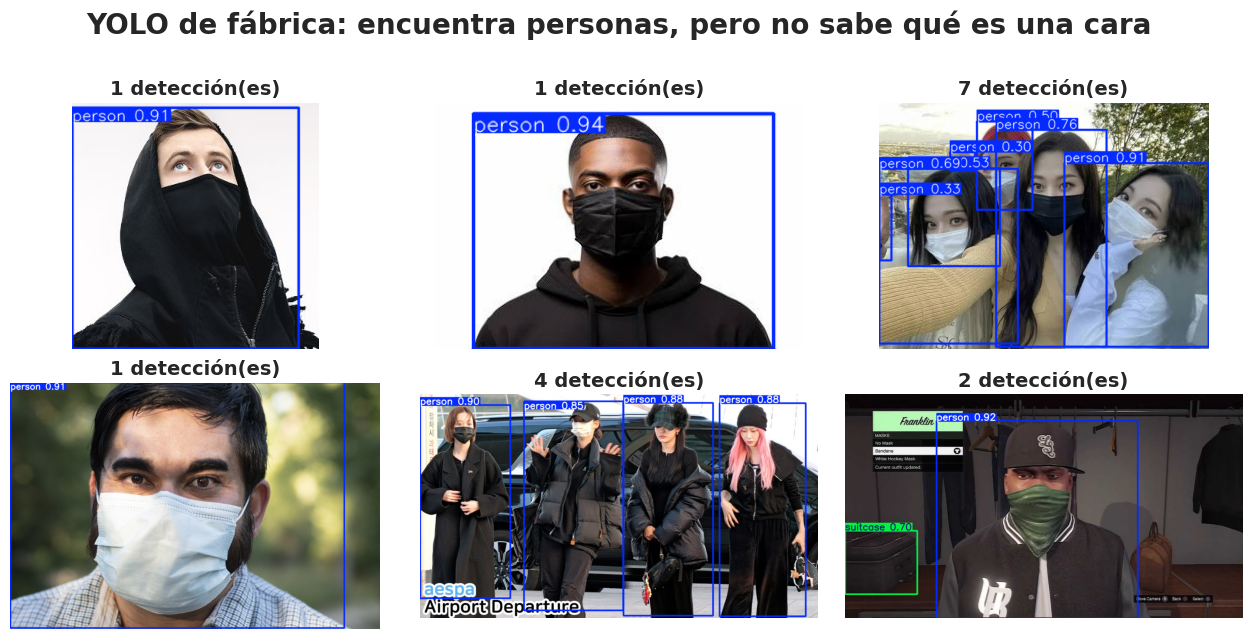

Gráfico guardado: f01_yolo_de_fabrica.png
Resultados guardados en: /content/resultados_c10/fabrica


,imagen,detecciones,clases
0,alan-walker-tickets_03-03-27_23_6aa2f1a04b4dc.jpg,1,person
1,images (1).jpg,1,person
2,images (2).jpg,7,person
3,man-5544589_1280.jpg,1,person
4,maxresdefault (2).jpg,4,person
5,maxresdefault.jpg,2,"person, suitcase"


In [10]:
# ============================================================
# PARTE 2B · Probarlo con fotos
# ============================================================
CARPETA_EJEMPLOS = BASE / "ejemplos"
ZIP_EJEMPLOS = BASE / "ejemplos.zip"
ID_DRIVE_EJEMPLOS = "1VTpG-jnF6mV6Mcgvg_XXdpyUvhkLX6GH"   # ejemplos.zip (nuestras fotos y video) en Google Drive
if not ZIP_EJEMPLOS.exists() and not CARPETA_EJEMPLOS.exists():
    try:
        import gdown
    except ImportError:
        import subprocess, sys
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
        import gdown
    try:
        gdown.download(id=ID_DRIVE_EJEMPLOS, output=str(ZIP_EJEMPLOS), quiet=True)
    except Exception as e:
        print("No se pudo bajar ejemplos.zip desde Drive:", e)
if ZIP_EJEMPLOS.exists() and not CARPETA_EJEMPLOS.exists():
    with zipfile.ZipFile(ZIP_EJEMPLOS) as z:
        z.extractall(CARPETA_EJEMPLOS)
EJEMPLOS = sorted(p for p in CARPETA_EJEMPLOS.rglob("*")
                  if p.suffix.lower() in EXTENSIONES and "__MACOSX" not in str(p)) if CARPETA_EJEMPLOS.exists() else []
if not EJEMPLOS:                                        # sin fotos propias: dos fotos de Ultralytics
    CARPETA_EJEMPLOS.mkdir(exist_ok=True)
    for archivo in ["bus.jpg", "zidane.jpg"]:
        urllib.request.urlretrieve(f"https://ultralytics.com/images/{archivo}", CARPETA_EJEMPLOS / archivo)
    EJEMPLOS = listar_imagenes(CARPETA_EJEMPLOS)
print("Fotos de ejemplo:", [p.name for p in EJEMPLOS])

tabla_fabrica = predecir_imagenes(PARAMETROS["modelo_base"], EJEMPLOS, RESULTADOS / "fabrica",
                                  "YOLO de fábrica: encuentra personas, pero no sabe qué es una cara",
                                  "f01_yolo_de_fabrica.png")
tabla_fabrica

---
# Parte 3 · El dataset: imágenes, cajas y el archivo YAML

Para que YOLO aprenda a detectar el uso de mascarilla necesita **imágenes** y, para cada una, **dónde están los rostros y si llevan mascarilla**. En formato YOLO eso son tres cosas:

1. Una carpeta `images/` con las fotos, separada en `train`, `val` y `test`.
2. Una carpeta `labels/` con **un archivo `.txt` por foto**, con el mismo nombre. Cada línea es una caja: `clase x_centro y_centro ancho alto`, todo dividido por el tamaño de la imagen (números entre 0 y 1).
3. Un archivo **`data.yaml`** que le dice a YOLO dónde están las carpetas y cómo se llama cada clase.

Usamos el dataset público "Mask Detection" de Roboflow Universe (848 fotos con 4.021 cajas ya etiquetadas, 3 clases). **No hubo que etiquetar nada a mano.**

**En su proyecto no se baja de Kaggle: suben un ZIP.** Escriban su nombre en `"dataset_zip"` de la configuración y la Parte 3A lo sube y lo descomprime (detalle en la Parte 11).

Si Kaggle pide autenticación, la celda te pedirá tu token: en kaggle.com, `Settings` → `API` → `Generate New Token`. **Nunca escribas tu token dentro del notebook**: si lo compartes, otros pueden usar tu cuenta.

In [11]:
# ============================================================
# PARTE 3A · El dataset: nuestro ZIP de Roboflow
# ============================================================
if PARAMETROS["dataset_zip"]:
    import zipfile, gdown

    DRIVE_ID = "1pdJGrAHgVNjug_CPRdUongSOxQL8VTSd"
    ZIP_DATOS = Path("/content/dataset.zip")
    ORIGEN = Path("/content/datos_zip")

    # Descargar solo si no está ya (evita repetir al re-ejecutar la celda)
    if not ZIP_DATOS.exists():
        gdown.download(id=DRIVE_ID, output=str(ZIP_DATOS), quiet=False)

    # Descomprimir en disco local
    if not ORIGEN.exists():
        ORIGEN.mkdir(parents=True)
        with zipfile.ZipFile(ZIP_DATOS) as z:
            z.extractall(ORIGEN)
else:
    # (rama de la clase: caras desde Kaggle; no se usa en este proyecto)
    import kagglehub
    os.environ.setdefault("KAGGLEHUB_CACHE", str(BASE / "kagglehub"))     # descarga junto al notebook
    try:
        ORIGEN = Path(kagglehub.dataset_download(PARAMETROS["dataset_kaggle"]))
    except Exception as error:
        print("Kaggle pidió autenticación:", type(error).__name__)
        os.environ["KAGGLE_API_TOKEN"] = getpass.getpass("Pega tu token de Kaggle (no se mostrará): ")
        ORIGEN = Path(kagglehub.dataset_download(PARAMETROS["dataset_kaggle"]))
print("Dataset original en:", ORIGEN)
for carpeta in sorted(p for p in ORIGEN.rglob("*") if p.is_dir()):
    n = len(list(carpeta.glob("*.*")))
    if n:
        print(f"  {carpeta.relative_to(ORIGEN)}: {n} archivos")

Downloading...
From: https://drive.google.com/uc?id=1pdJGrAHgVNjug_CPRdUongSOxQL8VTSd
To: /content/dataset.zip
100%|██████████| 17.2M/17.2M [00:00<00:00, 185MB/s]


Dataset original en: /content/datos_zip
  test/images: 127 archivos
  test/labels: 127 archivos
  train/images: 594 archivos
  train/labels: 594 archivos
  valid/images: 127 archivos
  valid/labels: 127 archivos


In [12]:
# ============================================================
# PARTE 3B · Train, Validation y Test + data.yaml
# ============================================================
if PARAMETROS["dataset_zip"]:
    NOMBRES = leer_nombres(ORIGEN / "data.yaml")               # las clases salen del data.yaml del ZIP
    print("Clases del ZIP:", NOMBRES)
    if PARAMETROS["clases"]:                                   # quedarse solo con 1 a 3 clases
        filtrar_clases(ORIGEN, BASE / "datos_filtrados", PARAMETROS["clases"])
        ORIGEN, NOMBRES = BASE / "datos_filtrados", dict(enumerate(PARAMETROS["clases"]))
DATA_YAML = crear_dataset_de_trabajo(ORIGEN, DATOS, NOMBRES, PARAMETROS["fraccion_test"], SEMILLA)
print("\nContenido de data.yaml:\n")
print(DATA_YAML.read_text(encoding="utf-8"))

conteo = contar_dataset(DATOS, NOMBRES)
NUMEROS["conteo"] = conteo.to_dict()
conteo

Clases del ZIP: {0: 'mask_weared_incorrect', 1: 'with_mask', 2: 'without_mask'}
El dataset ya trae train, val y test: se conservan.
Dataset de trabajo en: /content/datos_proyecto

Contenido de data.yaml:

path: /content/datos_proyecto
train: images/train
val: images/val
test: images/test
names:
  0: mask_weared_incorrect
  1: with_mask
  2: without_mask



,Imágenes,Cajas,Imágenes sin objetos,mask_weared_incorrect,with_mask,without_mask
Split,,,,,,
train,594,2925,0,90,2340,495
val,127,496,0,12,412,72
test,127,600,0,19,432,149


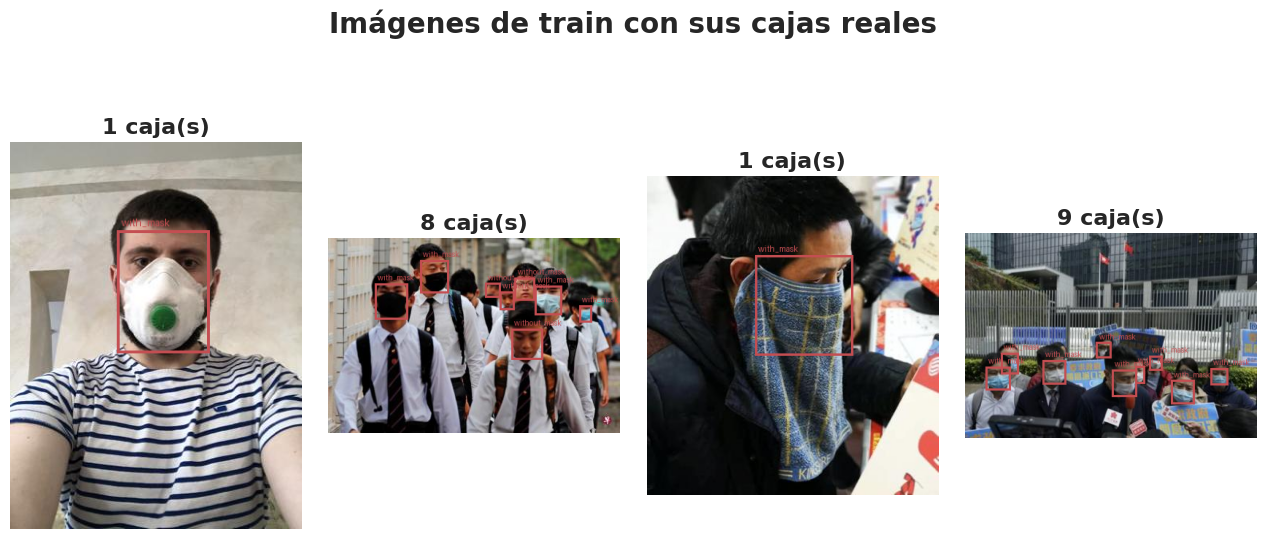

Gráfico guardado: f02_muestras_con_cajas.png


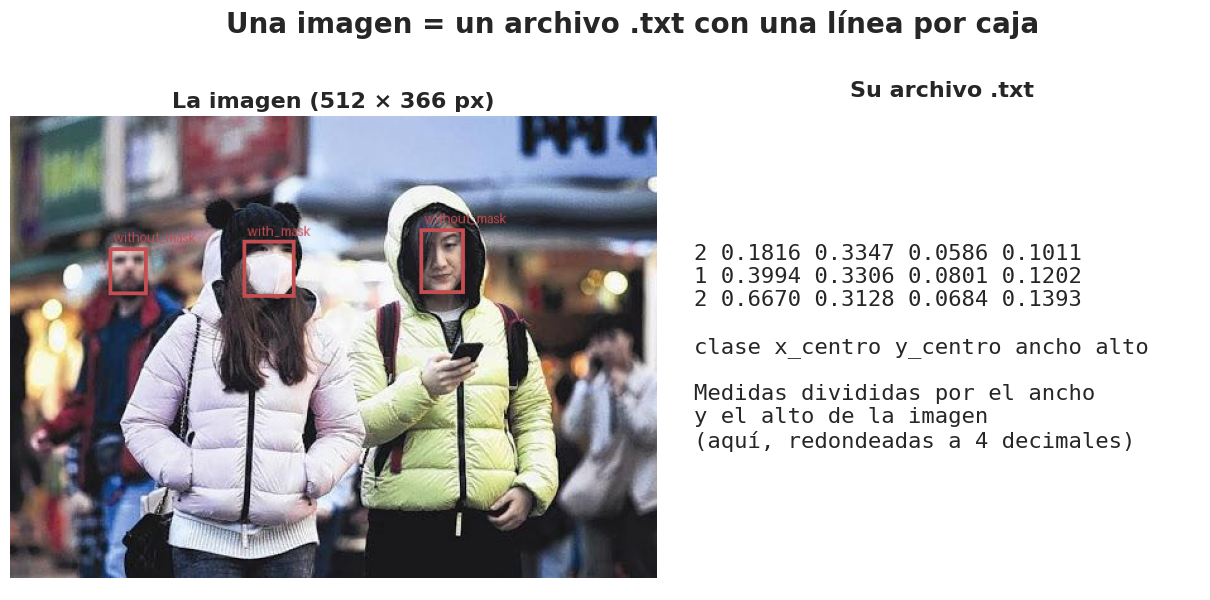

Gráfico guardado: f03_una_etiqueta_yolo.png


In [13]:
# ============================================================
# PARTE 3C · Ver las cajas: así se ve una etiqueta
# ============================================================
mostrar_muestras(DATOS, "train", NOMBRES, n=4, nombre="f02_muestras_con_cajas.png")
ruta_ejemplo, lineas_ejemplo = explicar_etiqueta(DATOS, "train", NOMBRES, nombre="f03_una_etiqueta_yolo.png")
NUMEROS["etiqueta_ejemplo"] = {"imagen": ruta_ejemplo.name, "lineas": lineas_ejemplo}

---
# Parte 4 · Transfer learning

Igual que con MobileNetV2 en la clase 09: partimos de un modelo que ya sabe ver y **congelamos el backbone** (las primeras capas, que detectan bordes, texturas y formas). Solo se entrenan las capas finales, que aprenden a reconocer las tres clases de mascarilla.

Para que alcance el tiempo de Colab gratis usamos **una parte del Train** (`fraccion_transfer`) e imágenes de 416 px.

**Paciencia:** si durante 10 épocas seguidas el modelo no mejora en Validation, el entrenamiento se detiene y se queda con la mejor época. Seguir entrenando ahí solo sobreajusta (la pérdida de Train sigue bajando y la de Validation sube) y gasta tiempo de Colab. Con 50 épocas sí puede activarse: en nuestro transfer learning se detuvo en la época 49 (la mejor fue la 39).

Ultralytics guarda todo en `runs_c10/transfer_learning/`: los pesos (`weights/best.pt`), las métricas por época (`results.csv`) y sus gráficos.

In [14]:
# ============================================================
# PARTE 4A · Entrenamiento con el backbone congelado
# ============================================================
RUTA_TL, SEGUNDOS_TL, RUN_TL = entrenar(
    PARAMETROS["modelo_base"],                 # 1) partimos de los pesos de COCO
    "transfer_learning",
    epocas=PARAMETROS["epocas_transfer"],      # 2) pocas épocas
    fraccion=PARAMETROS["fraccion_transfer"],  # 3) una parte del Train
    congelar=PARAMETROS["capas_congeladas"],   # 4) backbone congelado
    horas=PARAMETROS["horas_maximas_transfer"],
)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datos_proyecto/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=transfer_learning, nbs=64, nms=None, opset=None, optimize=F

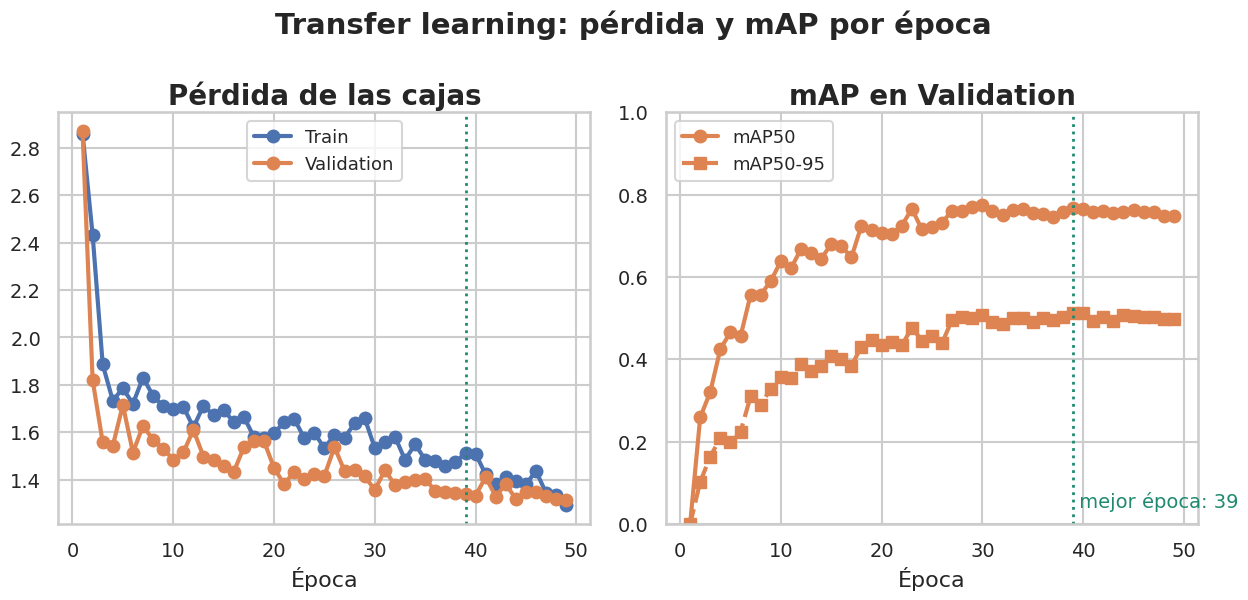

Gráfico guardado: f04_curvas_transfer.png
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 937.5±241.8 MB/s, size: 19.8 KB)
val: Scanning /content/datos_proyecto/labels/val.cache... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 28.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.3it/s 1.8s
                   all        127        496      0.838      0.712      0.764      0.508
Speed: 0.5ms preprocess, 3.7ms inference, 0.0ms loss, 3.8ms postprocess per image
Results saved to /content/runs_c10/eval_transfer_learning_val
transfer_learning en val: {'Precision': 0.838, 'Recall': 0.712, 'mAP50': 0.764, 'mAP50-95': 0.508}


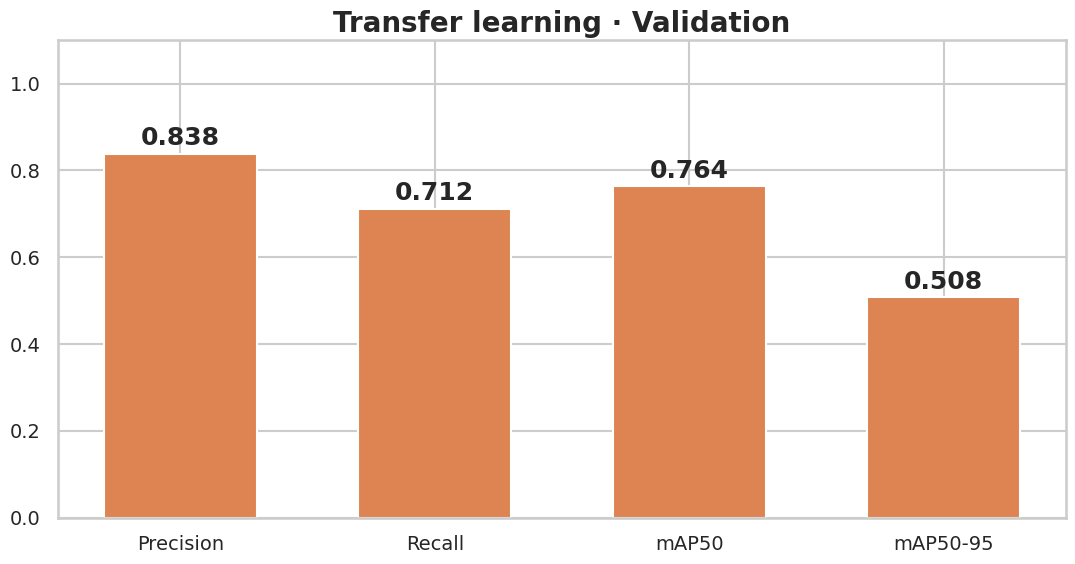

Gráfico guardado: f05_metricas_transfer_val.png


In [15]:
# ============================================================
# PARTE 4B · Curvas y métricas en Validation
# ============================================================
MEJOR_EPOCA_TL, EPOCAS_TL = graficar_curvas(RUN_TL, "Transfer learning: pérdida y mAP por época", "f04_curvas_transfer.png")
METRICAS_TL, EVAL_TL = evaluar(RUTA_TL, "val", "transfer_learning")
graficar_metricas(METRICAS_TL, "Transfer learning · Validation", "f05_metricas_transfer_val.png")
NUMEROS["transfer_learning"] = {"minutos": SEGUNDOS_TL / 60, "epocas": EPOCAS_TL,
                                "mejor_epoca": MEJOR_EPOCA_TL, "validation": METRICAS_TL}

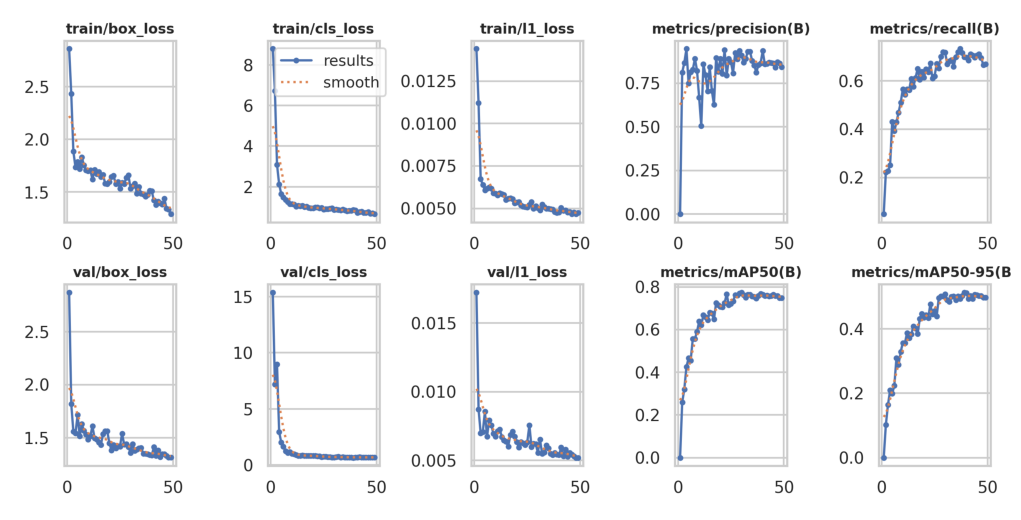

Gráfico guardado: f06_results_ultralytics.png


In [16]:
# ============================================================
# PARTE 4C · El resumen que arma Ultralytics
# ============================================================
copiar_figura(RUN_TL / "results.png", "f06_results_ultralytics.png")

---
# Parte 5 · ¿Cómo se mide un detector?

En clasificación bastaba comparar la clase predicha con la real. En detección también importa **dónde** quedó la caja.

- **IoU** (*Intersection over Union*): cuánto se superpone la caja predicha con la real. 1 es perfecta y 0, que no se tocan. Una detección cuenta como **acierto** si su IoU llega a un umbral, normalmente **0,5**.
- **Precision**: de todas las cajas que dibujó el modelo, qué parte correspondía de verdad a un rostro con esa clase. Baja cuando inventa detecciones.
- **Recall**: de todos los rostros reales (con su estado de mascarilla), qué parte encontró. Baja cuando se le escapan.
- Las dos dependen de la **confianza mínima**: si se exige más confianza, el modelo inventa menos detecciones (sube precision), pero se le escapan más (baja recall). La curva precision-recall muestra ese equilibrio.
- **mAP50**: resume precision y recall en todos los niveles de confianza, con IoU de 0,5. Es la métrica más usada.
- **mAP50-95**: lo mismo, pero exigiendo cajas cada vez más ajustadas (IoU de 0,50 a 0,95). Siempre es menor que mAP50.

Ojo: la precision y el recall que reporta Ultralytics están calculados en la confianza que da el mejor equilibrio entre ambos. Por eso no coinciden con el conteo de la Parte 5B, que usa la confianza mínima de 0,25 con que se dibujan las cajas.

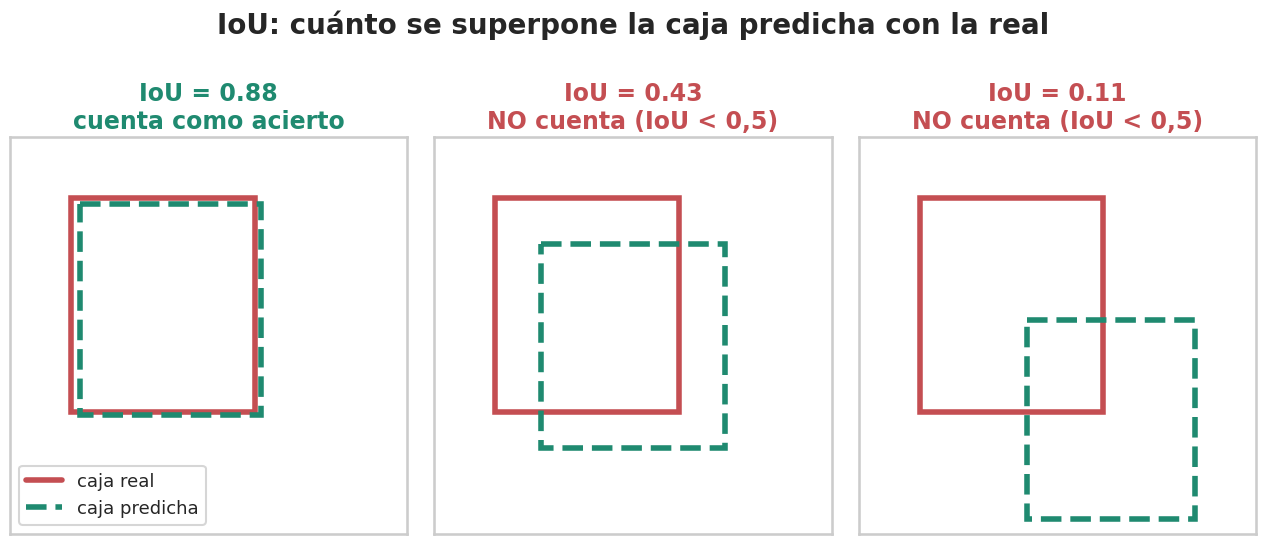

Gráfico guardado: f07_iou.png


In [17]:
# ============================================================
# PARTE 5A · IoU en un dibujo
# ============================================================
graficar_iou("f07_iou.png")

{'Aciertos': 438, 'Falsas detecciones': 66, 'Objetos perdidos': 58, 'Precision': 0.869, 'Recall': 0.883, 'Imágenes': 127}


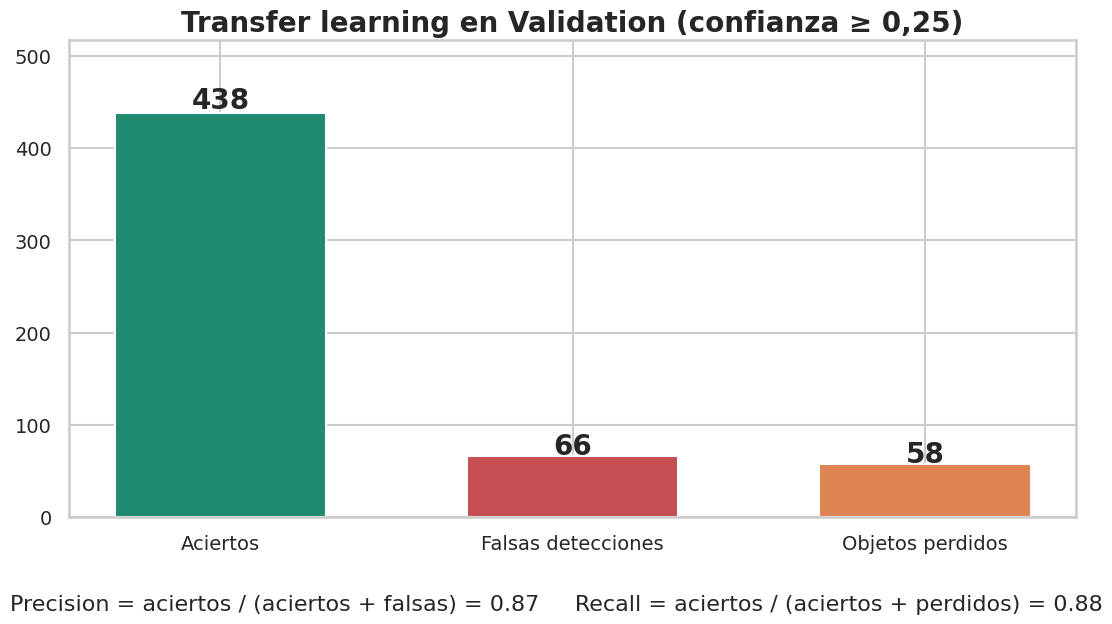

Gráfico guardado: f08_aciertos_falsas_perdidas.png


In [18]:
# ============================================================
# PARTE 5B · Aciertos, falsas detecciones y objetos perdidos (con confianza 0,25)
# ============================================================
ACIERTOS_TL = contar_aciertos(RUTA_TL, DATOS, "val", NOMBRES, conf=PARAMETROS["confianza"])
graficar_aciertos(ACIERTOS_TL, "Transfer learning en Validation (confianza ≥ 0,25)", "f08_aciertos_falsas_perdidas.png")
NUMEROS["transfer_learning"]["aciertos_val"] = ACIERTOS_TL

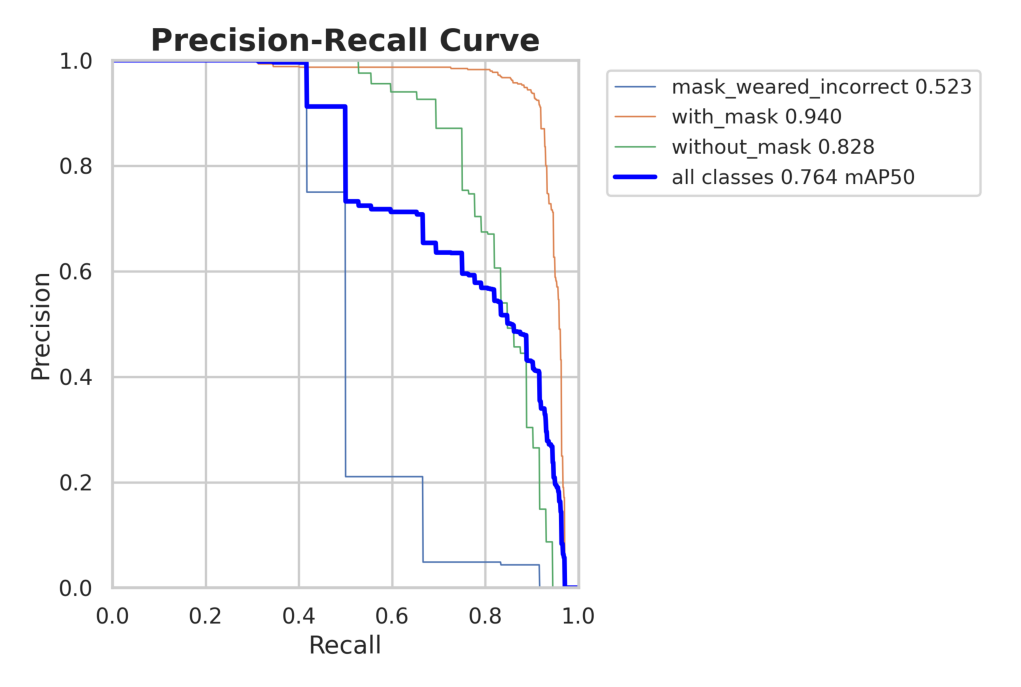

Gráfico guardado: f09_curva_pr.png


In [19]:
# ============================================================
# PARTE 5C · Curva precision-recall: qué pasa al mover la confianza mínima
# ============================================================
copiar_figura(EVAL_TL / "BoxPR_curve.png", "f09_curva_pr.png")

---
# Parte 6 · Fine tuning

Ahora **descongelamos todo** y seguimos entrenando desde el mejor modelo del transfer learning, con un **learning rate bajo** para ajustar sin romper lo aprendido. Es la misma idea de la clase 09.

In [20]:
# ============================================================
# PARTE 6A · Entrenamiento con todas las capas
# ============================================================
RUTA_FT, SEGUNDOS_FT, RUN_FT = entrenar(
    RUTA_TL,                                      # 1) partimos del mejor modelo anterior
    "fine_tuning",
    epocas=PARAMETROS["epocas_fine_tuning"],
    fraccion=PARAMETROS["fraccion_fine_tuning"],
    congelar=None,                                # 2) nada congelado
    optimizador="AdamW",                          # 3) optimizador explícito para que respete lr0
    lr0=PARAMETROS["lr_fine_tuning"],             # 4) learning rate bajo
    horas=PARAMETROS["horas_maximas_fine_tuning"],
)

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datos_proyecto/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs_c10/transfer_learning/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fine_tuning, n

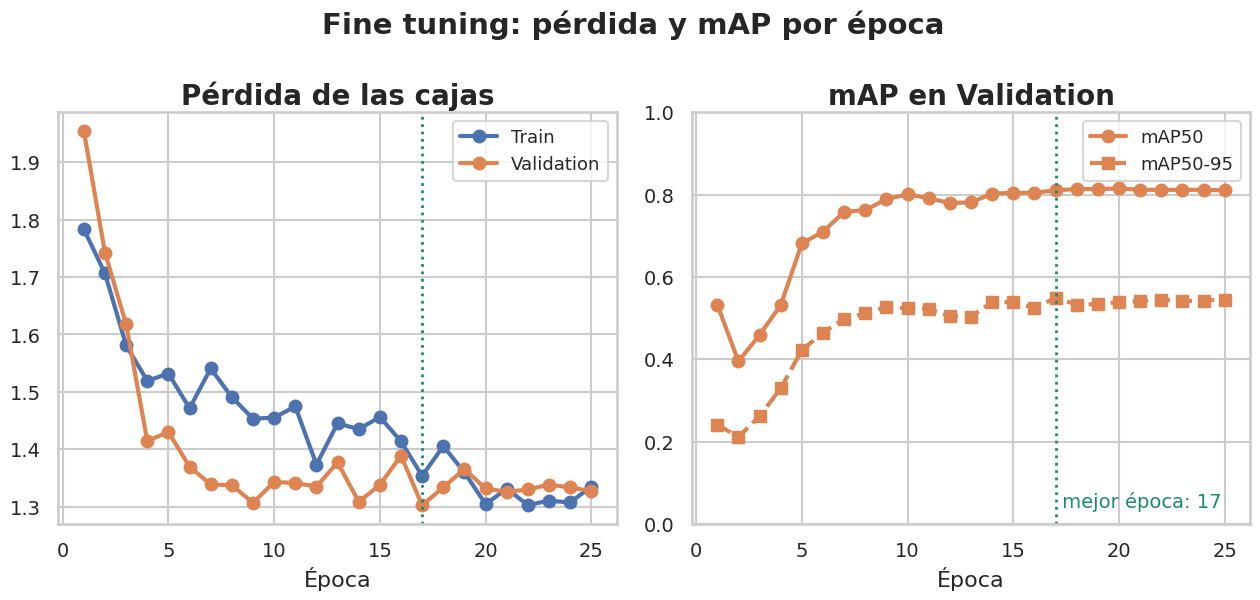

Gráfico guardado: f10_curvas_fine_tuning.png
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 620.6±351.1 MB/s, size: 18.0 KB)
val: Scanning /content/datos_proyecto/labels/val.cache... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 41.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.3it/s 1.9s
                   all        127        496      0.954      0.699      0.815      0.551
Speed: 0.8ms preprocess, 3.2ms inference, 0.0ms loss, 3.1ms postprocess per image
Results saved to /content/runs_c10/eval_fine_tuning_val
fine_tuning en val: {'Precision': 0.954, 'Recall': 0.699, 'mAP50': 0.815, 'mAP50-95': 0.551}


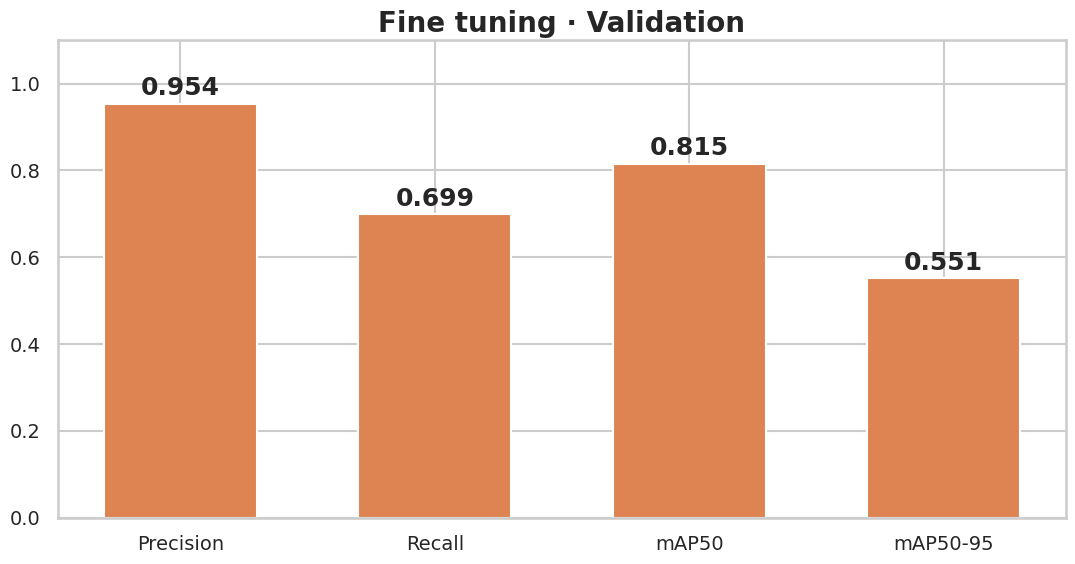

Gráfico guardado: f11_metricas_fine_tuning_val.png


In [21]:
# ============================================================
# PARTE 6B · Curvas y métricas en Validation
# ============================================================
MEJOR_EPOCA_FT, EPOCAS_FT = graficar_curvas(RUN_FT, "Fine tuning: pérdida y mAP por época", "f10_curvas_fine_tuning.png")
METRICAS_FT, EVAL_FT = evaluar(RUTA_FT, "val", "fine_tuning")
graficar_metricas(METRICAS_FT, "Fine tuning · Validation", "f11_metricas_fine_tuning_val.png")
NUMEROS["fine_tuning"] = {"minutos": SEGUNDOS_FT / 60, "epocas": EPOCAS_FT,
                          "mejor_epoca": MEJOR_EPOCA_FT, "validation": METRICAS_FT}

---
# Parte 7 · Comparar los modelos con Validation

**Regla, decidida antes de mirar Test:** nos quedamos con el modelo de **mayor mAP50-95 en Validation**.

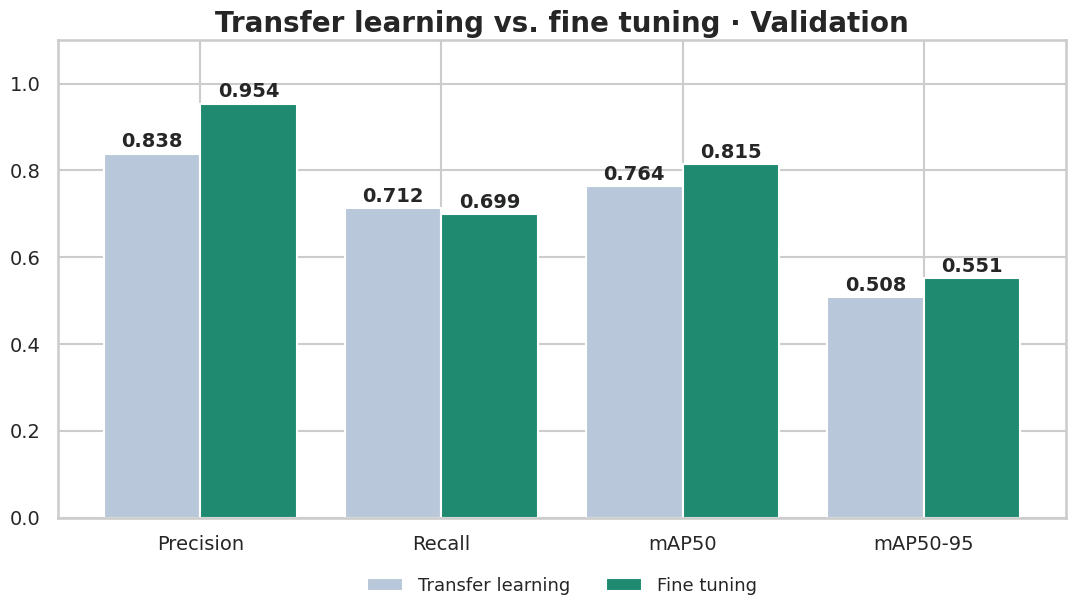

Gráfico guardado: f12_comparacion_validation.png
Modelo elegido: Fine tuning


In [22]:
# ============================================================
# PARTE 7A · Elegir con Validation
# ============================================================
CANDIDATOS = {"Transfer learning": (RUTA_TL, METRICAS_TL), "Fine tuning": (RUTA_FT, METRICAS_FT)}
ELEGIDO = max(CANDIDATOS, key=lambda k: CANDIDATOS[k][1]["mAP50-95"])
RUTA_ELEGIDO = CANDIDATOS[ELEGIDO][0]
comparar_modelos({k: v[1] for k, v in CANDIDATOS.items()}, "Transfer learning vs. fine tuning · Validation",
                 "f12_comparacion_validation.png", elegido=ELEGIDO)
print("Modelo elegido:", ELEGIDO)
NUMEROS["elegido"] = ELEGIDO

{'Aciertos': 430, 'Falsas detecciones': 41, 'Objetos perdidos': 66, 'Precision': 0.913, 'Recall': 0.867, 'Imágenes': 127}


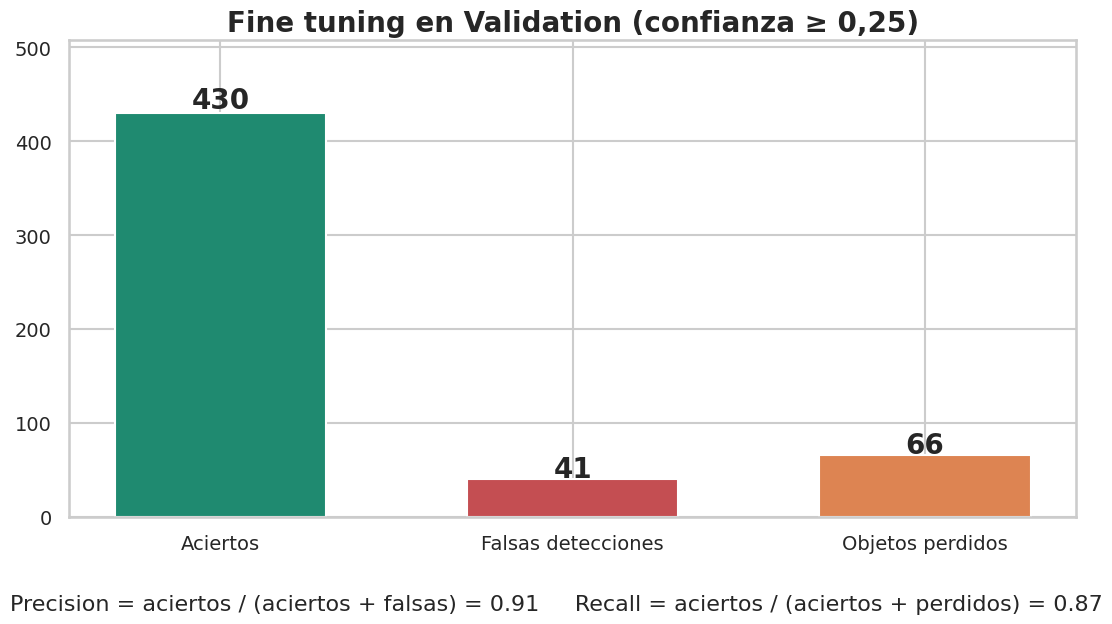

Gráfico guardado: f12b_aciertos_fine_tuning_val.png

Métricas en Validation


,Precision,Recall,mAP50,mAP50-95
Transfer learning,0.838,0.712,0.764,0.508
Fine tuning,0.954,0.699,0.815,0.551


Conteo con confianza ≥ 0,25 en Validation


,Aciertos,Falsas detecciones,Objetos perdidos,Precision,Recall
Transfer learning,438.0,66.0,58.0,0.869,0.883
Fine tuning,430.0,41.0,66.0,0.913,0.867


Configuración de cada entrenamiento


Entrenamiento,Transfer learning,Fine tuning
Modelo base,yolo26n.pt,best.pt del transfer learning
Épocas (máx.),50,25
Épocas corridas,49,25
Mejor época,39,17
imgsz,416,416
Fracción Train,1.0,1.0
Capas congeladas,10,0
Optimizador,auto,AdamW (lr0=0.0005)
GPU,Tesla T4,Tesla T4
Minutos,4.2,2.3


In [23]:
# ============================================================
# PARTE 7B · Aciertos, falsas y perdidos del fine tuning + tablas resumen
# ============================================================
ACIERTOS_FT = contar_aciertos(RUTA_FT, DATOS, "val", NOMBRES, conf=PARAMETROS["confianza"])
graficar_aciertos(ACIERTOS_FT, "Fine tuning en Validation (confianza ≥ 0,25)", "f12b_aciertos_fine_tuning_val.png")
NUMEROS["fine_tuning"]["aciertos_val"] = ACIERTOS_FT

print("\nMétricas en Validation")
display(pd.DataFrame({"Transfer learning": METRICAS_TL, "Fine tuning": METRICAS_FT}).T.round(3))

print("Conteo con confianza ≥ 0,25 en Validation")
display(pd.DataFrame({"Transfer learning": ACIERTOS_TL, "Fine tuning": ACIERTOS_FT}).T.drop(columns="Imágenes").round(3))

print("Configuración de cada entrenamiento")
CONFIG = pd.DataFrame([
    {"Entrenamiento": "Transfer learning", "Modelo base": PARAMETROS["modelo_base"],
     "Épocas (máx.)": PARAMETROS["epocas_transfer"], "Épocas corridas": EPOCAS_TL, "Mejor época": MEJOR_EPOCA_TL,
     "imgsz": PARAMETROS["imgsz"], "Fracción Train": PARAMETROS["fraccion_transfer"],
     "Capas congeladas": PARAMETROS["capas_congeladas"], "Optimizador": "auto", "GPU": NOMBRE_GPU,
     "Minutos": round(SEGUNDOS_TL / 60, 1)},
    {"Entrenamiento": "Fine tuning", "Modelo base": "best.pt del transfer learning",
     "Épocas (máx.)": PARAMETROS["epocas_fine_tuning"], "Épocas corridas": EPOCAS_FT, "Mejor época": MEJOR_EPOCA_FT,
     "imgsz": PARAMETROS["imgsz"], "Fracción Train": PARAMETROS["fraccion_fine_tuning"],
     "Capas congeladas": 0, "Optimizador": f"AdamW (lr0={PARAMETROS['lr_fine_tuning']})", "GPU": NOMBRE_GPU,
     "Minutos": round(SEGUNDOS_FT / 60, 1)},
]).set_index("Entrenamiento").T
display(CONFIG)
NUMEROS["configuracion"] = CONFIG.to_dict()

**Qué significan estas cifras en nuestro problema (fine tuning, Validation, confianza ≥ 0,25):**
- **Acierto (430):** el modelo dibujó una caja con la clase correcta (`with_mask`, `without_mask` o `mask_weared_incorrect`) y IoU ≥ 0,5 con la caja real.
- **Falsa detección (41):** el modelo dibujó una caja que no corresponde a una persona con esa clase. Incluye el caso en que detecta bien el rostro pero se equivoca de clase (por ejemplo, dice `with_mask` cuando la persona no la usa), que cuenta a la vez como falsa y como perdido. Es el error más delicado: alguien sin mascarilla queda marcado como que cumple.
- **Objeto perdido (66):** una persona con su estado real que el modelo no detectó. Es la persona que el sistema no revisa.
- En la comparación, el fine tuning tiene más precision pero menos recall que el transfer learning (0,954 vs 0,838 y 0,699 vs 0,712 en las métricas de Ultralytics). Es decir, inventa menos, pero se le escapan más personas.

**Regla de elección (definida antes de mirar Test):** mayor mAP50-95 en Validation. Fine tuning (0,551) supera a transfer learning (0,508), así que es el modelo elegido.

### Métricas por clase en Validation
Cada línea muestra `[precision, recall, mAP50, mAP50-95]` de una clase. Primero el **fine tuning** y después el **transfer learning**. Cajas en Validation: `mask_weared_incorrect` 12, `with_mask` 412, `without_mask` 72.

In [24]:
m = YOLO(RUTA_FT).val(data=str(DATA_YAML), split="val", imgsz=PARAMETROS["imgsz"],
                      batch=16, conf=0.001, device=DISPOSITIVO, plots=False, verbose=False)
print("clase | precision | recall | mAP50 | mAP50-95")
for i, c in enumerate(m.box.ap_class_index):
    print(m.names[c], [round(float(x), 3) for x in m.box.class_result(i)])

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 601.9±186.4 MB/s, size: 17.1 KB)
val: Scanning /content/datos_proyecto/labels/val.cache... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 22.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 7.4it/s 1.1s
                   all        127        496      0.954      0.699      0.815      0.551
Speed: 0.4ms preprocess, 2.6ms inference, 0.0ms loss, 1.5ms postprocess per image
clase | precision | recall | mAP50 | mAP50-95
mask_weared_incorrect [0.976, 0.583, 0.684, 0.482]
with_mask [0.983, 0.82, 0.937, 0.638]
without_mask [0.903, 0.694, 0.823, 0.534]


In [25]:
m = YOLO(RUTA_TL).val(data=str(DATA_YAML), split="val", imgsz=PARAMETROS["imgsz"],
                      batch=16, conf=0.001, device=DISPOSITIVO, plots=False, verbose=False)
print("clase | precision | recall | mAP50 | mAP50-95")
for i, c in enumerate(m.box.ap_class_index):
    print(m.names[c], [round(float(x), 3) for x in m.box.class_result(i)])

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 977.0±352.0 MB/s, size: 20.1 KB)
val: Scanning /content/datos_proyecto/labels/val.cache... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 35.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 9.6it/s 0.8s
                   all        127        496      0.838      0.712      0.764      0.508
Speed: 0.4ms preprocess, 2.0ms inference, 0.0ms loss, 1.2ms postprocess per image
clase | precision | recall | mAP50 | mAP50-95
mask_weared_incorrect [0.745, 0.488, 0.523, 0.369]
with_mask [0.94, 0.898, 0.94, 0.63]
without_mask [0.83, 0.75, 0.828, 0.524]


**Qué muestran las cifras por clase (Validation):**
- **`with_mask`** (412 cajas) es la clase que mejor se detecta, con mAP50 de 0,94 en ambos modelos.
- **`without_mask`** (72 cajas): mAP50 de 0,82 y 0,83. El recall es **0,69 en el fine tuning** (0,75 en el transfer learning): con la confianza que optimiza el equilibrio, aproximadamente 3 de cada 10 personas sin mascarilla no se detectan. Es la clase más importante para el uso en urgencias.
- **`mask_weared_incorrect`** (solo 12 cajas): mAP50 de 0,68 con fine tuning contra 0,52 con transfer learning. **La ventaja del fine tuning está casi toda en esta clase**; en las otras dos los modelos son prácticamente iguales. Con 12 cajas, unas pocas detecciones cambian mucho el resultado, así que esta diferencia hay que leerla con cautela.

---
# Parte 8 · Evaluación final con Test

Test se usa **una sola vez**, con el modelo elegido y **al mismo tamaño de imagen del entrenamiento**: si se evalúa a otro tamaño, las métricas cambian.

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 707.4±241.5 MB/s, size: 26.4 KB)
val: Scanning /content/datos_proyecto/labels/test... 127 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 127/127 1.9Kit/s 0.1s
val: New cache created: /content/datos_proyecto/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.2it/s 1.9s
                   all        127        600      0.869      0.676      0.781      0.458
Speed: 0.8ms preprocess, 3.0ms inference, 0.0ms loss, 3.3ms postprocess per image
Results saved to /content/runs_c10/eval_elegido_test
elegido en test: {'Precision': 0.869, 'Recall': 0.676, 'mAP50': 0.781, 'mAP50-95': 0.458}


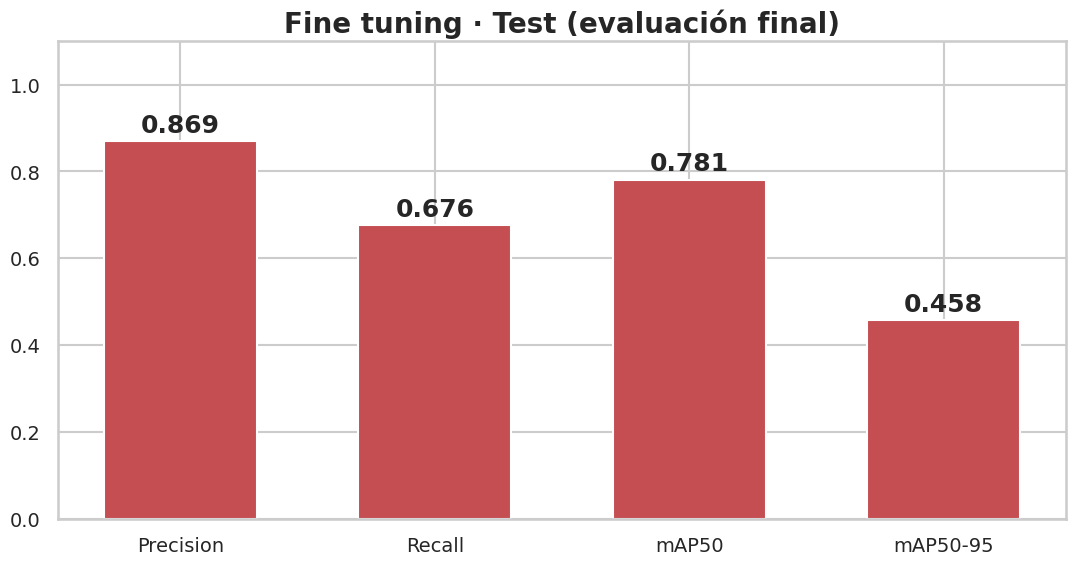

Gráfico guardado: f13_metricas_test.png


In [26]:
# ============================================================
# PARTE 8A · Métricas en Test
# ============================================================
METRICAS_TEST, EVAL_TEST = evaluar(RUTA_ELEGIDO, "test", "elegido")
graficar_metricas(METRICAS_TEST, f"{ELEGIDO} · Test (evaluación final)", "f13_metricas_test.png", color=TEST)
NUMEROS["test"] = METRICAS_TEST

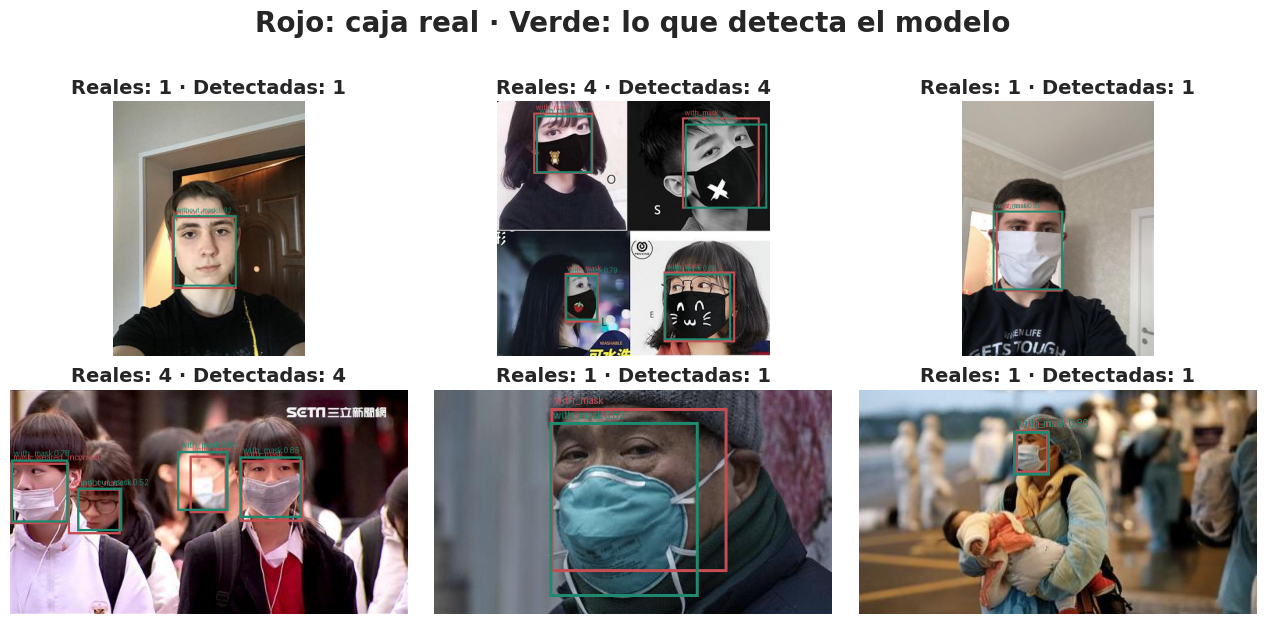

Gráfico guardado: f14_real_vs_detectado_test.png


In [27]:
# ============================================================
# PARTE 8B · Cajas reales vs. detectadas en Test
# ============================================================
galeria_real_vs_predicho(RUTA_ELEGIDO, DATOS, "test", NOMBRES, n=6, nombre="f14_real_vs_detectado_test.png")

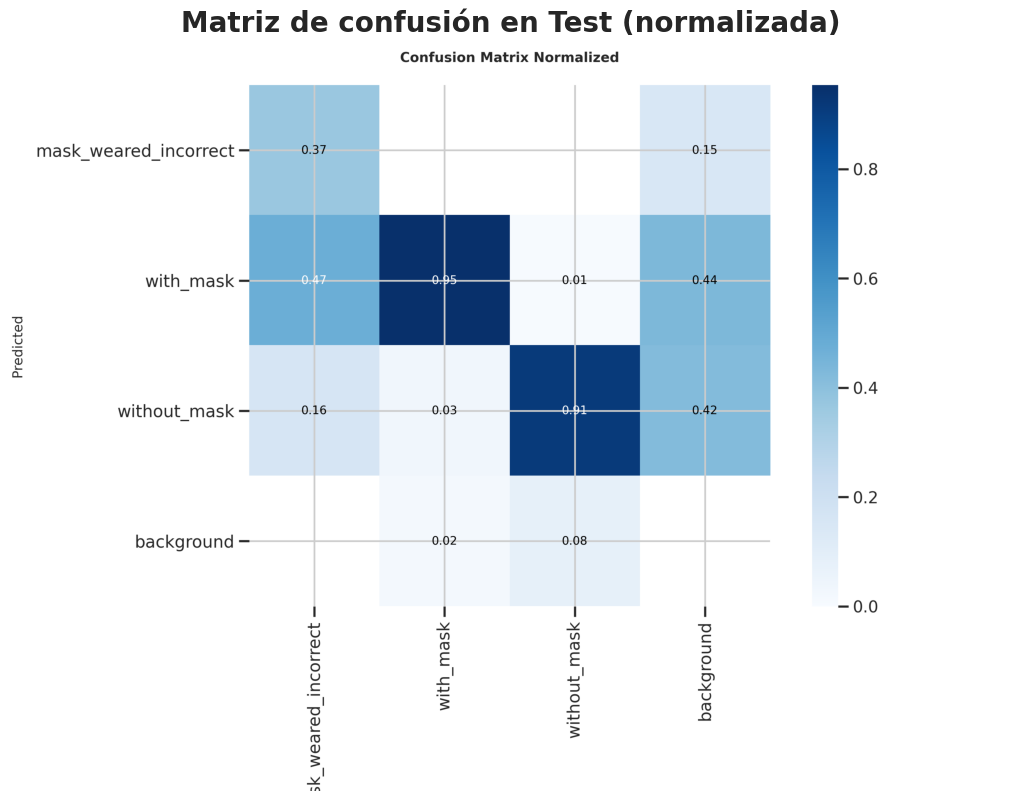

Gráfico guardado: f14a_matriz_confusion_test.png


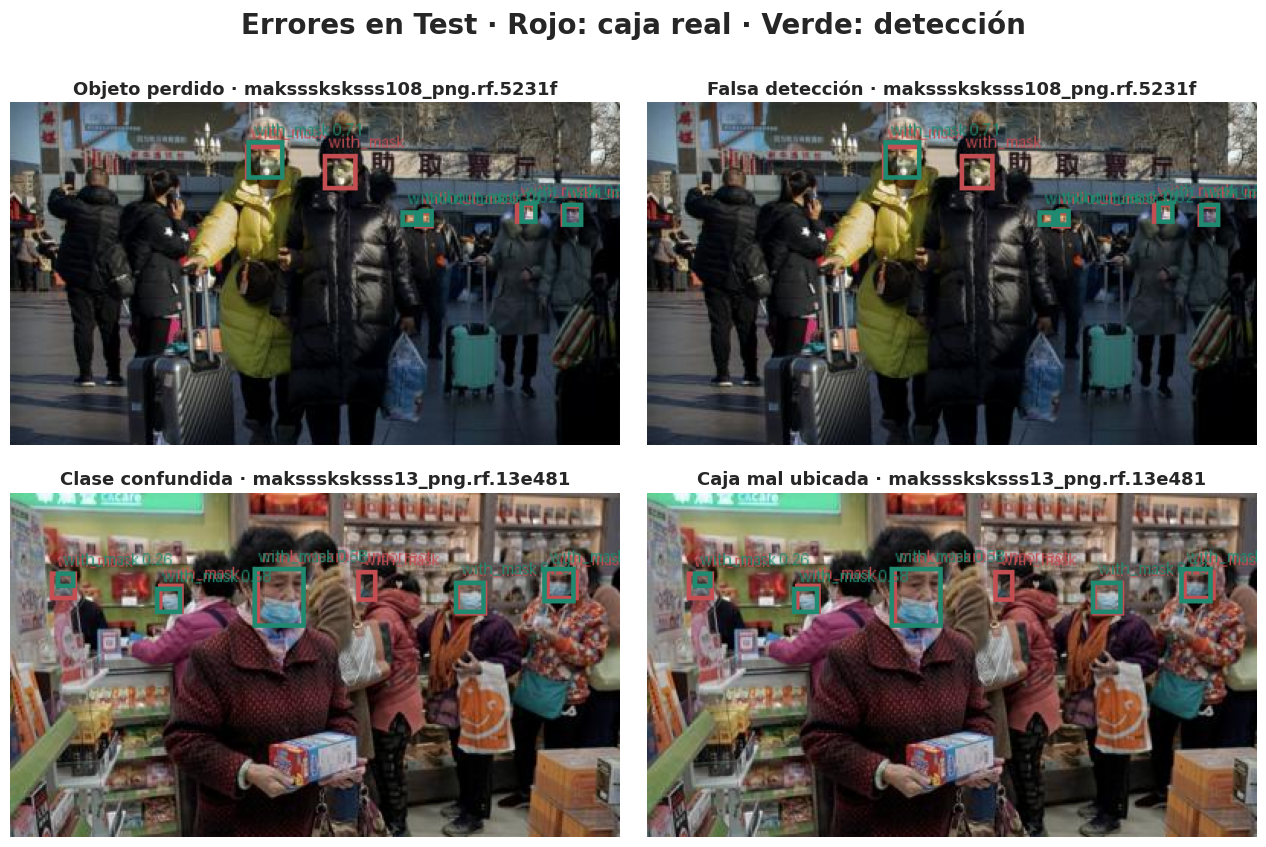

Gráfico guardado: f14b_errores_test.png
Cantidad de cada tipo de error en Test: {'Objeto perdido': 87, 'Falsa detección': 31, 'Clase confundida': 16, 'Caja mal ubicada': 6}


In [28]:
# ============================================================
# PARTE 8C · Matriz de confusión (de la evaluación ya hecha) y ejemplos de error
# ============================================================
copiar_figura(EVAL_TEST / "confusion_matrix_normalized.png", "f14a_matriz_confusion_test.png",
              "Matriz de confusión en Test (normalizada)")

def buscar_errores(ruta_pesos, raiz, split, nombres, conf):
    '''Busca un ejemplo de cada tipo de error y cuenta cuántos hay.'''
    modelo = YOLO(ruta_pesos)
    casos = {"Objeto perdido": None, "Falsa detección": None, "Clase confundida": None, "Caja mal ubicada": None}
    cuenta = dict.fromkeys(casos, 0)
    for ruta in listar_imagenes(Path(raiz) / "images" / split):
        img = cargar_imagen(ruta)
        reales = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        r = modelo.predict(img, imgsz=PARAMETROS["imgsz"], conf=conf, device=DISPOSITIVO, verbose=False)[0]
        pred = [(int(c), *xyxy) for c, xyxy in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist())]
        confs = r.boxes.conf.tolist()
        hallados = []
        for cr, *caja in reales:
            ious = [iou(caja, p[1:]) for p in pred]
            if not ious or max(ious) < 0.1:
                hallados.append("Objeto perdido")
                continue
            k = int(np.argmax(ious))
            if ious[k] >= 0.5 and pred[k][0] != cr:
                hallados.append("Clase confundida")
            elif ious[k] < 0.5 and pred[k][0] == cr:
                hallados.append("Caja mal ubicada")
        for p in pred:
            if all(iou(p[1:], rr[1:]) < 0.1 for rr in reales):
                hallados.append("Falsa detección")
        for tipo in hallados:
            cuenta[tipo] += 1
            if casos[tipo] is None:
                casos[tipo] = (ruta, reales, pred, confs)
    mostrar = {t: c for t, c in casos.items() if c}
    fig, ejes = grilla(len(mostrar), columnas=2, alto_fila=4.2)
    for ax, (tipo, (ruta, reales, pred, confs)) in zip(ejes, mostrar.items()):
        img = dibujar_cajas(cargar_imagen(ruta), reales, nombres, TEST)
        img = dibujar_cajas(img, pred, nombres, MEJOR, confianzas=confs)
        ax.imshow(img)
        ax.set_title(f"{tipo} · {ruta.name[:28]}", fontsize=13)
        ax.axis("off")
    fig.suptitle("Errores en Test · Rojo: caja real · Verde: detección", fontsize=20, fontweight="bold")
    fig.tight_layout()
    guardar_figura("f14b_errores_test.png")
    print("Cantidad de cada tipo de error en Test:", cuenta)

buscar_errores(RUTA_ELEGIDO, DATOS, "test", NOMBRES, PARAMETROS["confianza"])

### Resultado en Test y tres errores comentados
**Test (una sola evaluación, modelo elegido, 416 px):** precision 0,869 · recall 0,676 · mAP50 0,781 · mAP50-95 0,458. Respecto de Validation (0,551 de mAP50-95) baja unos 0,09. Es esperable en parte porque el modelo se eligió con Validation, y además Test tiene otra composición (149 cajas `without_mask` y 19 `mask_weared_incorrect`, contra 72 y 12 en Validation). Con tan pocos ejemplos de la clase minoritaria no podemos separar cuánto es azar y cuánto es un límite real del modelo.

**Errores en Test (confianza ≥ 0,25):** 87 objetos perdidos, 31 falsas detecciones, 16 clases confundidas y 6 cajas mal ubicadas, sobre 600 cajas reales. En la matriz de confusión normalizada, `with_mask` se acierta en 0,95 y `without_mask` en cerca de 0,91, pero `mask_weared_incorrect` solo en 0,37: el 0,47 de esas caras se predice como `with_mask` y el 0,16 como `without_mask`.

1. **Objeto perdido** (`maksssksksss108`): en primer plano hay dos personas con mascarilla. La de chaqueta amarilla se detecta como `with_mask` (confianza 0,71), pero la del abrigo negro, de al lado, tiene caja real y ninguna detección. Posibles causas (hipótesis): capucha y pelo oscuros que rodean el rostro, poco contraste y rostro parcialmente tapado. En el problema real es la persona a la que el sistema no revisa. En el fondo de la misma imagen hay además caras diminutas con cajas muy pequeñas, que es el caso más difícil.
2. **Falsa detección:** hubo 31 en todo Test (alrededor de 5 % de las cajas reales). Según la matriz, las falsas detecciones se reparten sobre todo entre `with_mask` (0,44) y `without_mask` (0,42), y menos en `mask_weared_incorrect` (0,15). Es el error más delicado cuando el modelo marca `with_mask` donde no hay una persona con mascarilla, porque hace parecer que se cumple la norma. La figura reutiliza la imagen 108 porque muestra el primer caso de cada tipo.
3. **Clase confundida** (`maksssksksss13`): la mujer del primer plano lleva la mascarilla bajo la nariz (caja real `mask_weared_incorrect`) y el modelo la marca como `with_mask` con confianza 0,58. Coincide con la matriz de confusión y con que esta clase tiene solo 90 ejemplos en Train: el modelo reconoce que hay una mascarilla, pero distingue mal su posición. **Caja mal ubicada:** en la misma imagen, en varios rostros pequeños la caja detectada queda algo desfasada respecto de la real (6 casos en todo Test, el error menos frecuente).

---
# Parte 9 · Usar el modelo con imágenes y con video

Entrenar necesita GPU. **Usar** el modelo entrenado, no tanto: cada imagen toma milisegundos y funciona también en la CPU de un notebook.

- **Imágenes:** las fotos de `ejemplos/`. Los resultados quedan en `resultados_c10/imagenes/`.
- **Video:** si subes un video llamado `video_prueba.mp4` junto al notebook (o un `.mp4` dentro de `ejemplos/`), se usa ese. Si no, se arma uno con fotos de Test. El video con las cajas queda en `resultados_c10/video_detectado.mp4`.

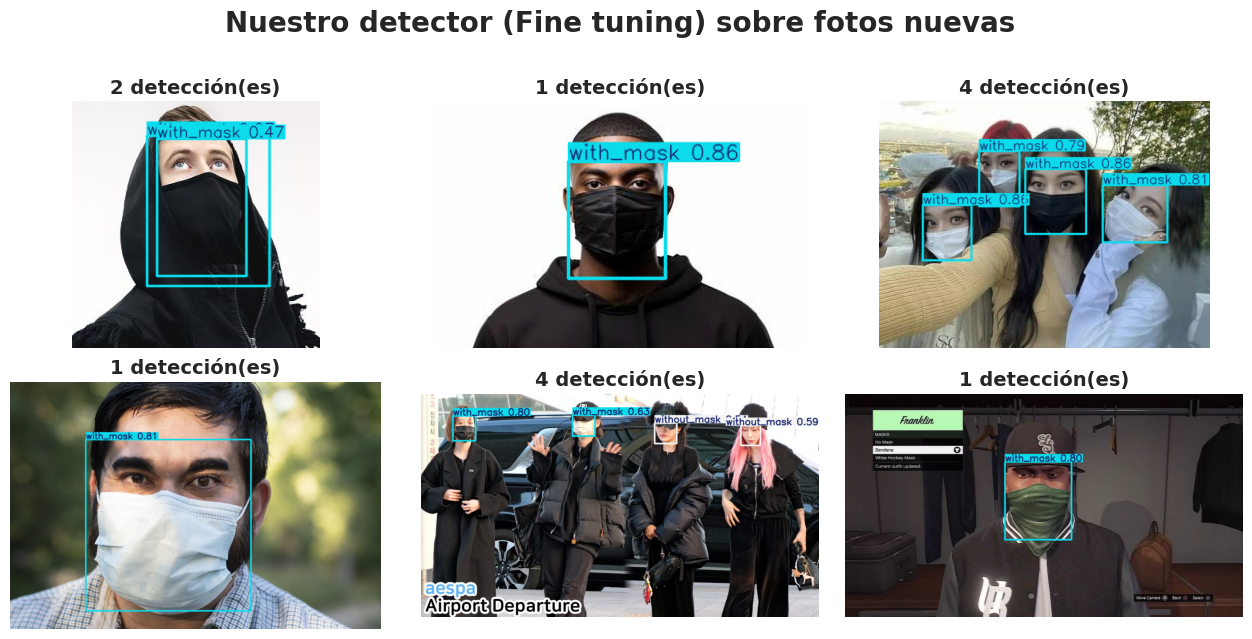

Gráfico guardado: f15_detector_en_fotos.png
Resultados guardados en: /content/resultados_c10/imagenes


,imagen,detecciones,clases
0,alan-walker-tickets_03-03-27_23_6aa2f1a04b4dc.jpg,2,with_mask
1,images (1).jpg,1,with_mask
2,images (2).jpg,4,with_mask
3,man-5544589_1280.jpg,1,with_mask
4,maxresdefault (2).jpg,4,"with_mask, without_mask"
5,maxresdefault.jpg,1,with_mask


In [29]:
# ============================================================
# PARTE 9A · Imágenes
# ============================================================
tabla_imagenes = predecir_imagenes(RUTA_ELEGIDO, EJEMPLOS, RESULTADOS / "imagenes",
                                   f"Nuestro detector ({ELEGIDO}) sobre fotos nuevas",
                                   "f15_detector_en_fotos.png")
tabla_imagenes

306 cuadros procesados (10.2 s de video). Velocidad media: 49.3 cuadros por segundo. Guardado en /content/resultados_c10/video_detectado.mp4


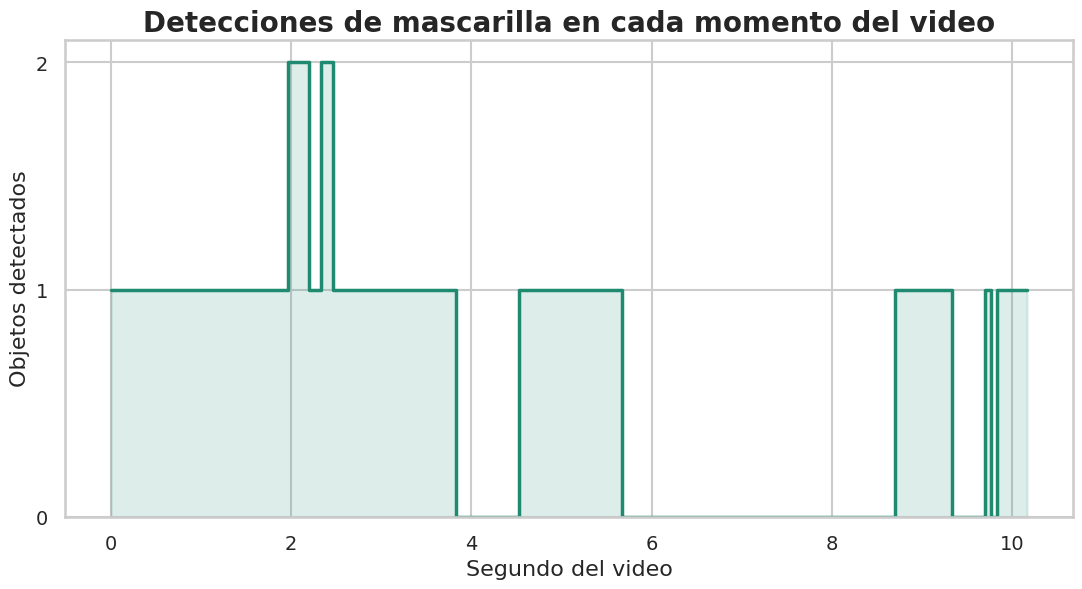

Gráfico guardado: f16_detecciones_por_cuadro.png


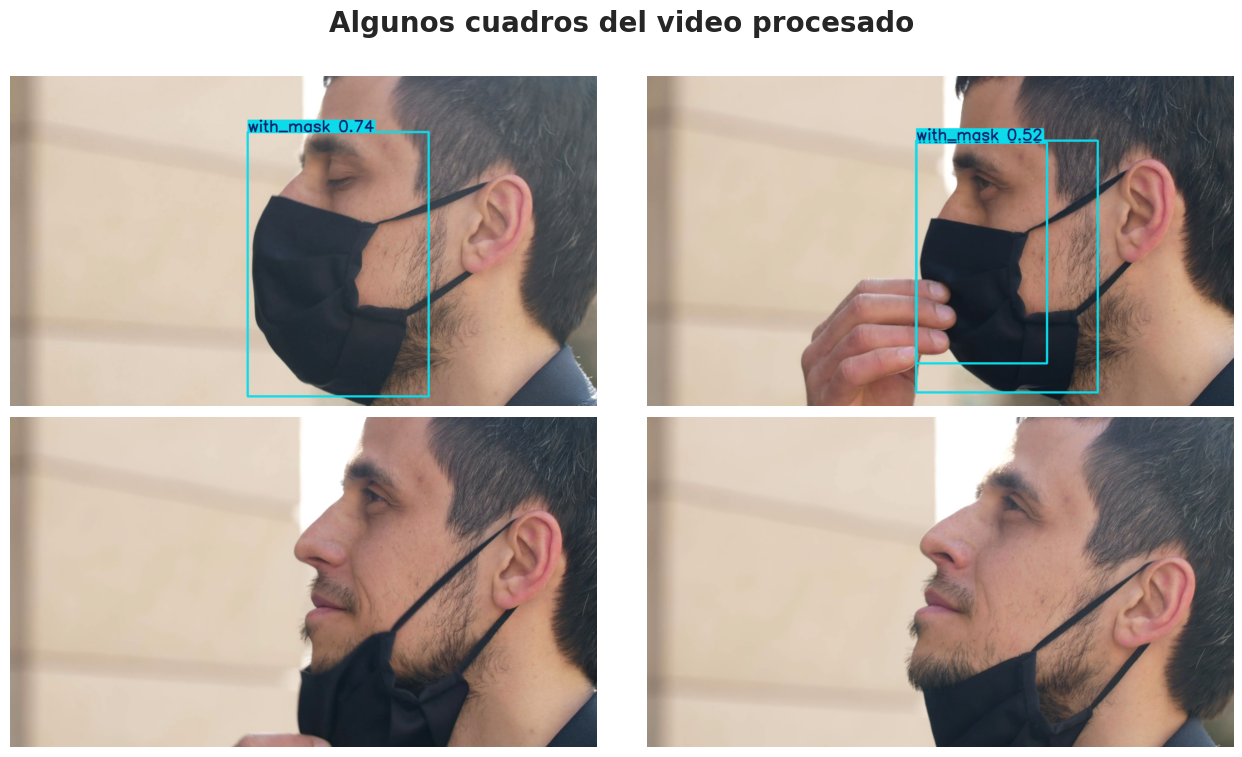

Gráfico guardado: f17_cuadros_video.png


In [30]:
# ============================================================
# PARTE 9B · Video
# ============================================================
VIDEO = BASE / "video_prueba.mp4"
if not VIDEO.exists() and CARPETA_EJEMPLOS.exists():            # también sirve un .mp4 dentro de ejemplos/
    videos = sorted(CARPETA_EJEMPLOS.rglob("*.mp4"))
    VIDEO = videos[0] if videos else VIDEO
if not VIDEO.exists():
    print("No hay video_prueba.mp4: se arma uno con 10 fotos de Test.")
    VIDEO = crear_video_desde_imagenes(listar_imagenes(DATOS / "images" / "test")[:10],
                                       RESULTADOS / "video_desde_fotos.mp4")
tabla_video, cuadros = predecir_video(RUTA_ELEGIDO, VIDEO, RESULTADOS / "video_detectado.mp4")
graficar_detecciones_por_cuadro(tabla_video, "Detecciones de mascarilla en cada momento del video", "f16_detecciones_por_cuadro.png")
galeria_cuadros(cuadros, "Algunos cuadros del video procesado", "f17_cuadros_video.png")
NUMEROS["video"] = {"cuadros": len(tabla_video), "fps_procesamiento": float(1000 / tabla_video["ms"].mean()),
                    "detecciones_promedio": float(tabla_video["detecciones"].mean())}

---
# Parte 10 · Guardar el modelo y los resultados

Todo lo importante queda en `resultados_c10/` y en un ZIP para descargar. **Descárgalo antes de cerrar Colab**: al cortarse la sesión se borra.

- `modelos/transfer_learning.pt`, `modelos/fine_tuning.pt` y `modelos/modelo_elegido.pt`: los pesos. Pesan unos pocos MB.
- `figuras/`: todos los gráficos.
- `numeros_c10.json`: las cifras (tiempos, épocas y métricas).
- `imagenes/` y `video_detectado.mp4`: los resultados de la Parte 9.

Para cargar el modelo después, en cualquier computador: `YOLO("modelo_elegido.pt")`.

**Para la Evaluación 04** me entregan `modelos/modelo_elegido.pt` y sus dos videos: el `.pt` lo abro con el panel de demostración en mi computador y lo corro en vivo.

In [31]:
# ============================================================
# PARTE 10A · Modelos, cifras y ZIP
# ============================================================
MODELOS = RESULTADOS / "modelos"
MODELOS.mkdir(exist_ok=True)
shutil.copy2(RUTA_TL, MODELOS / "transfer_learning.pt")
shutil.copy2(RUTA_FT, MODELOS / "fine_tuning.pt")
shutil.copy2(RUTA_ELEGIDO, MODELOS / "modelo_elegido.pt")
for run in (RUN_TL, RUN_FT):
    shutil.copy2(run / "results.csv", RESULTADOS / f"results_{run.name}.csv")
NUMEROS["mb_modelo"] = (MODELOS / "modelo_elegido.pt").stat().st_size / 1e6

with open(RESULTADOS / "numeros_c10.json", "w", encoding="utf-8") as f:
    json.dump(NUMEROS, f, ensure_ascii=False, indent=2, default=str)

ZIP = BASE / "resultados_c10.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in RESULTADOS.rglob("*"):
        if archivo.is_file():
            z.write(archivo, archivo.relative_to(BASE))
print(f"ZIP listo: {ZIP} ({ZIP.stat().st_size / 1e6:.1f} MB)")
print(f"El modelo elegido pesa {NUMEROS['mb_modelo']:.1f} MB")

ZIP listo: /content/resultados_c10.zip (35.6 MB)
El modelo elegido pesa 5.4 MB


In [32]:
# ============================================================
# PARTE 10B · Descargar (solo en Colab)
# ============================================================
if Path("/content").exists():
    from google.colab import files
    files.download(str(ZIP))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# Parte 11 · Para tu proyecto: su dataset desde un ZIP

Para las Evaluaciones 03 y 04 cambian el dataset y vuelven a correr el notebook completo. Yo bajé las caras desde Kaggle; **ustedes suben un ZIP**:

1. En Roboflow Universe, en la página del dataset: `Download Dataset` → formato **YOLO** (YOLOv11 o YOLO26: es el mismo formato) → `Download zip to computer`. No hace falta API key.
2. En la configuración, escriban el nombre del ZIP en `"dataset_zip"` (por ejemplo, `"papas.zip"`). Si trae más de 3 clases, escriban las que se quedan en `"clases"`, con los nombres exactos de su `data.yaml`: `filtrar_clases` las renumera y escribe un `data.yaml` nuevo.
3. Ejecuten todo. En este proyecto la Parte 3A descarga el ZIP desde Google Drive con `gdown`; en otro proyecto, cambien `DRIVE_ID` por el ID de su ZIP (que debe estar compartido como «cualquier persona con el enlace»).
4. Si el ZIP pesa cientos de MB, la subida directa puede tardar mucho: súbanlo a Google Drive y escriban su ruta (`"/content/drive/MyDrive/papas.zip"`). La celda monta Drive sola.
5. Cambien los títulos de los gráficos que dicen «caras».
6. **Revisen la licencia** del dataset en su página.

**Cuidado con la fuga de datos.** Muchas versiones de Roboflow traen **copias aumentadas** (la misma foto girada, recortada o con otro brillo) solo en Train. **No juntes todo para volver a repartir**: copias de una misma foto terminarían en Train y en Test, y las métricas saldrían infladas. Usa la partición que trae la versión, o una versión sin aumentos.

La celda 11A muestra otra forma de bajar el dataset, con la API de Roboflow. No es necesaria si suben el ZIP.

In [33]:
# ============================================================
# PARTE 11A · Otra forma (opcional): bajar con la API de Roboflow (cambia USAR_ROBOFLOW a True)
# ============================================================
USAR_ROBOFLOW = False

if USAR_ROBOFLOW:
    %pip install -q roboflow
    from roboflow import Roboflow
    rf = Roboflow(api_key=getpass.getpass("Pega tu API key de Roboflow (no se mostrará): "))
    proyecto = rf.workspace("material-identification").project("garbage-classification-3")  # cópialo de la página
    descarga = proyecto.version(2).download("yolov11", location=str(BASE / "datos_roboflow"))
    # Si el dataset trae más de 3 clases, quédate con las que te interesan:
    # (usa los nombres exactos que aparecen en el data.yaml descargado)
    DATA_YAML = filtrar_clases(BASE / "datos_roboflow", BASE / "datos_proyecto", ["PLASTIC", "GLASS", "CARDBOARD"])
    # Y desde aquí repites las Partes 3C a 10 con este DATA_YAML.

---
# Cierre · Qué observamos en este laboratorio

1. **Detectar es clasificar y además ubicar.** Cada objeto trae una caja, una clase y una confianza.
2. **El formato YOLO son tres piezas:** las imágenes, un `.txt` por imagen con las cajas y un `data.yaml` con las rutas y los nombres de las clases.
3. **No partimos de cero.** El modelo de fábrica no conocía las clases de mascarilla, pero con transfer learning aprendió a detectarlas en minutos; el fine tuning ajusta el resultado.
4. **Las métricas de detección** miran también la posición: IoU, precision, recall, mAP50 y mAP50-95. Test se usa una sola vez y al mismo tamaño de imagen del entrenamiento.
5. **Entrenar pide GPU; usar el modelo, no tanto.** El `.pt` pesa pocos MB y funciona con imágenes y con video en cualquier computador.